# Obtención de offsets de Venus (un notebook)

In [2]:
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u
import numpy as np
import pandas as pd

In [ ]:
#### Pasamos las coordenadas RA y DEC de grados decimales a grados sexagesimales

# 1. Cargar el DataFrame desde venus_metadata.txt
df = pd.read_csv('/content/drive/MyDrive/proyecto 2026-2/venus_metadata.txt', sep='\t')

# 2. Conversión a coordenadas astrónomas
coords = SkyCoord(ra=df['RA'].values * u.deg, dec=df['DEC'].values * u.deg)

# 3. Crear las nuevas columnas formateadas en sexagesimal
df['RA_SEXA'] = coords.ra.to_string(unit=u.hour, sep=':', precision=2, pad=True)
df['DEC_SEXA'] = coords.dec.to_string(unit=u.degree, sep=':', precision=2, pad=True, alwayssign=True)

# 4. Mostrar las primeras filas en pantalla
print(df[['FILENAME', 'RA', 'DEC', 'RA_SEXA', 'DEC_SEXA']].head())

# 5. Guardar el nuevo DataFrame con las coordenadas convertidas
df.to_csv('venus_metadata_pointing.txt', sep='\t', index=False)

In [ ]:
#### Obtención de los offset a partir de horizons y los header de datos

# --- 1. Rutas de archivos ---
ruta_horizons = 'horizons_results.txt'
ruta_fits = 'venus_metadata.txt'
# archivo_salida = 'venus_pointings_offsets.txt'

# --- 2. Leer y parsear JPL Horizons ---
with open(ruta_horizons, 'r') as f:
    contenido = f.read()

# Extraer el bloque entre $$SOE y $$EOE
bloque_datos = contenido.split('$$SOE')[1].split('$$EOE')[0].strip()

filas_h = []
for linea in bloque_datos.split('\n'):
    linea_limpia = linea.strip()
    if not linea_limpia:
        continue
    partes = linea_limpia.split()

    # Verificar que la línea tenga suficientes columnas
    if len(partes) > 8:
        # Reconstruir fecha UT
        fecha_str = f"{partes[0]} {partes[1]}"

        # Parsear RA (h m s) y DEC (d m s) de Horizons
        ra_h_str = f"{partes[3]}h{partes[4]}m{partes[5]}s"
        dec_h_str = f"{partes[6]}d{partes[7]}m{partes[8]}s"

        filas_h.append({
            'Date_UT': pd.to_datetime(fecha_str, format='%Y-%b-%d %H:%M:%S.%f'),
            'RA_H_str': ra_h_str,
            'DEC_H_str': dec_h_str
        })

df_horizons = pd.DataFrame(filas_h)

# Convertir las coordenadas de Horizons a grados decimales usando Astropy
coord_horizons = SkyCoord(df_horizons['RA_H_str'], df_horizons['DEC_H_str'], frame='icrs')
df_horizons['RA_H_deg'] = coord_horizons.ra.deg
df_horizons['DEC_H_deg'] = coord_horizons.dec.deg

# --- 3. Leer metadata de los FITS ---
df_fits = pd.read_csv(ruta_fits, sep='\t')

# Asegurar que la columna DATE esté en formato datetime
df_fits['DATE_UT'] = pd.to_datetime(df_fits['DATE'])

# Ordenar DataFrames por fecha para poder hacer merge_asof
df_fits = df_fits.sort_values('DATE_UT')
df_horizons = df_horizons.sort_values('Date_UT')

# --- 4. Merge por fecha cercana (merge_asof) ---
df = pd.merge_asof(
    df_fits,
    df_horizons[['Date_UT', 'RA_H_deg', 'DEC_H_deg']],
    left_on='DATE_UT',
    right_on='Date_UT',
    direction='nearest',
    tolerance=pd.Timedelta('5s')  # Margen de tolerancia de 5 segundos
)

# --- 5. Calcular Offsets en arcsec respecto al centro de Venus ---
# Usamos RA y DEC en grados decimales que vienen de tus FITS:
ra_fits = df['RA'].values
dec_fits = df['DEC'].values
ra_hor = df['RA_H_deg'].values
dec_hor = df['DEC_H_deg'].values

# Delta RA ajustado por cos(DEC) y Delta DEC, pasados a arcsec (* 3600)
df['offset_ra_arcsec'] = (ra_fits - ra_hor) * np.cos(np.radians(dec_hor)) * 3600.0
df['offset_dec_arcsec'] = (dec_fits - dec_hor) * 3600.0

# --- 6. Guardar resultados ---
cols_export = [
    'FILENAME', 'DATE', 'DPR_TYPE', 'SEQ_ARM',
    'RA', 'DEC', 'RA_H_deg', 'DEC_H_deg',
    'offset_ra_arcsec', 'offset_dec_arcsec'
]

# Mantener columnas de formato sexagesimal si existen en el archivo de entrada
if 'RA_SEXA' in df.columns and 'DEC_SEXA' in df.columns:
    cols_export.insert(6, 'RA_SEXA')
    cols_export.insert(7, 'DEC_SEXA')

df_resultado = df[cols_export]
# df_resultado.to_csv(archivo_salida, sep='\t', index=False)

print(f"Cálculo completado exitosamente. Archivo guardado como: {archivo_salida}")
print("\nPrimeras filas del resultado:")
print(df_resultado[['FILENAME', 'DPR_TYPE', 'SEQ_ARM', 'offset_ra_arcsec', 'offset_dec_arcsec']].head())

In [3]:
df = pd.read_csv('venus_pointings_offsets.txt', sep='\\s+')

df.head() # visualización de la tabla

,FILENAME,DATE,DPR_TYPE,SEQ_ARM,RA,DEC,RA_SEXA,DEC_SEXA,RA_H_deg,DEC_H_deg,offset_ra_arcsec,offset_dec_arcsec,n_pointing
0,XSHOO.2021-11-17T00:30:46.819.fits,2021-11-17T00:30:46.819,OBJECT,UVB,281.275568,-26.77101,18:45:06.14,-26:46:15.64,281.276875,-26.770861,-4.200873,-0.536,1
1,XSHOO.2021-11-17T00:30:52.080.fits,2021-11-17T00:30:52.080,OBJECT,VIS,281.275610,-26.77100,18:45:06.15,-26:46:15.60,281.276917,-26.770861,-4.199802,-0.500,1
2,XSHOO.2021-11-17T00:30:55.412.fits,2021-11-17T00:30:55.4126,OBJECT,NIR,281.275674,-26.77100,18:45:06.16,-26:46:15.60,281.276958,-26.770861,-4.128019,-0.500,1
3,XSHOO.2021-11-17T00:31:05.102.fits,2021-11-17T00:31:05.1017,OBJECT,NIR,281.275780,-26.77099,18:45:06.19,-26:46:15.56,281.277083,-26.770833,-4.189089,-0.564,1
4,XSHOO.2021-11-17T00:31:33.513.fits,2021-11-17T00:31:33.513,OBJECT,UVB,281.275865,-26.77098,18:45:06.21,-26:46:15.53,281.277375,-26.770806,-4.853345,-0.628,1


# Observational Map of Venus's Disk (otro notebook)

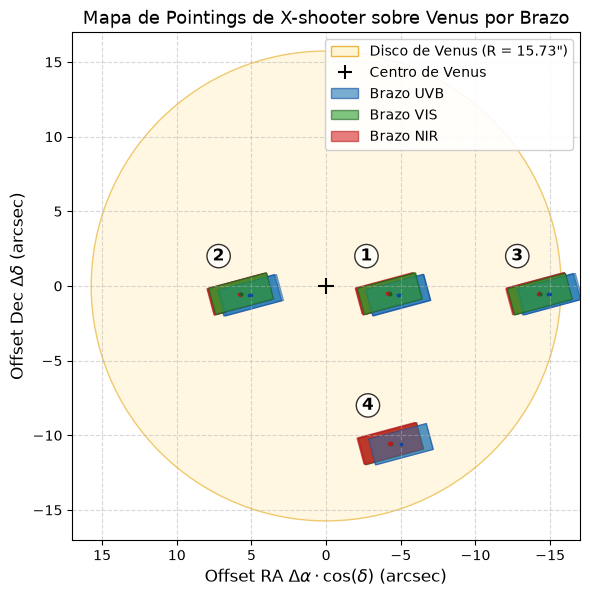

In [4]:
import matplotlib.pyplot as plt
from astropy.coordinates import SkyCoord
import astropy.units as u
import numpy as np
import pandas as pd
import matplotlib.patches as patches
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

#### MAPA DE POINTINGS de cada observación ####

# 1. Cargamos los datos
df = pd.read_csv('venus_pointings_offsets.txt', sep='\\s+')

fig, ax = plt.subplots(figsize=(6, 7))

# 2. Geometría de Venus y del instrumento X-shooter
r_venus = 31.467 / 2.0  # Radio semidiametro en arcsec (~15.73")
ifu_w = 1.8              # Ancho IFU (arcsec)
ifu_h = 4.0              # Largo IFU (arcsec)
pos_ang = -105.03660     # Ángulo de posición del rotador

# Definir mapa de colores por brazo (SEQ_ARM)
color_map = {
    'UVB': {'face': '#1f77b4', 'edge': '#0d47a1'},  # Azul
    'VIS': {'face': '#2ca02c', 'edge': '#1b5e20'},  # Verde
    'NIR': {'face': '#d62728', 'edge': '#b71c1c'}   # Rojo
}

# 3. Dibujar el disco y centro de Venus
disco_venus = plt.Circle((0, 0), r_venus, facecolor='#fff3cd', edgecolor='#e6a817', alpha=0.6)
ax.add_patch(disco_venus)
ax.plot(0, 0, 'k+', markersize=12, markeredgewidth=1.5)

# 4. Dibujar las rendijas/pointings coloreadas por brazo
for idx, row in df.iterrows():
    dx = row['offset_ra_arcsec']
    dy = row['offset_dec_arcsec']
    arm = row.get('SEQ_ARM', 'UVB')

    # Obtener configuración de color según el brazo
    colors = color_map.get(arm, {'face': 'gray', 'edge': 'black'})

    # Crear el parche de la rendija rotada desde su centro
    rect = patches.Rectangle(
        (dx - ifu_w / 2.0, dy - ifu_h / 2.0),
        ifu_w, ifu_h,
        angle=pos_ang,
        rotation_point='center',
        linewidth=0.8,
        edgecolor=colors['edge'],
        facecolor=colors['face'],
        alpha=0.5
    )
    ax.add_patch(rect)

    # Marcar el centro del pointing
    ax.plot(dx, dy, '.', color=colors['edge'], markersize=3)

# 5. Construir leyenda personalizada
legend_elements = [
    Patch(facecolor='#fff3cd', edgecolor='#e6a817', alpha=0.8, label=f'Disco de Venus (R = {r_venus:.2f}\")'),
    Line2D([0], [0], marker='+', color='k', label='Centro de Venus', linestyle='None', markersize=10, markeredgewidth=1.5)
]

#Agregar a la leyenda únicamente los brazos presentes en los datos
brazos_presentes = df['SEQ_ARM'].unique() if 'SEQ_ARM' in df.columns else ['UVB', 'VIS', 'NIR']
for arm in ['UVB', 'VIS', 'NIR']:
    if arm in brazos_presentes:
        c = color_map[arm]
        legend_elements.append(
            Patch(facecolor=c['face'], edgecolor=c['edge'], alpha=0.6, label=f'Brazo {arm}')
        )

ax.legend(handles=legend_elements, loc='upper right', framealpha=0.9, fontsize=10)

# Extra: etiquetas de cada pointing
etiquetas = [
    (-4.2, -0.5, '1'),   # Centro
    (5.7, -0.5, '2'),    # Izquierda 
    (-14.3, -0.5, '3'),  # Derecha
    (-4.3, -10.5, '4')   # Abajo
]

for x, y, texto in etiquetas:
    ax.annotate(texto, 
                xy=(x, y), 
                xytext=(x + 1.5, y + 2.5), # Pequeño desplazamiento para que no tape el centro
                fontsize=12, 
                fontweight='bold',
                color='black',
                ha='center',
                va='center',
                bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec="black", alpha=0.8))


# 6. Configuración de ejes y orientación astronómica
lim = 17  # En arcsec (cubre pointings centrales y tomas de cielo a ~95")
ax.set_xlim(lim, -lim)  # Invierte el eje X para que el Este quede a la izquierda
ax.set_ylim(-lim, lim)
ax.set_aspect('equal')

ax.set_xlabel(r'Offset RA $\Delta\alpha \cdot \cos(\delta)$ (arcsec)', fontsize=12)
ax.set_ylabel(r'Offset Dec $\Delta\delta$ (arcsec)', fontsize=12)
ax.set_title('Mapa de Pointings de X-shooter sobre Venus por Brazo', fontsize=13)

ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
# plt.savefig('mapa_pointings_venus_arms.png', dpi=300)
plt.show()

In [3]:
import matplotlib.patches as patches
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

def graficar_pointings_individuales(df, indices=[0, 1], zoom_auto=True):
    """
    Grafica únicamente los pointings seleccionados por su índice de fila en el DataFrame.

    Parámetros:
    -----------
    df : pandas.DataFrame
        DataFrame cargado desde 'venus_pointings_offsets.txt'.
    indices : list of int
        Índices de las filas que se quieren visualizar (ej: [0], [0, 1], [10, 11]).
    zoom_auto : bool
        Si es True, hace un zoom automático alrededor de los pointings seleccionados.
        Si es False, muestra la vista general completa con todo el disco de Venus.
    """
    # Validar índices
    indices_validos = [i for i in indices if 0 <= i < len(df)]
    if not indices_validos:
        print("Error: Ningún índice proporcionado existe en el DataFrame.")
        return

    sub_df = df.iloc[indices_validos].copy()

    fig, ax = plt.subplots(figsize=(5, 5))

    # Geometría de Venus y del instrumento X-shooter
    r_venus = 31.467 / 2.0  # ~15.73 arcsec
    ifu_w = 1.8              # arcsec
    ifu_h = 4.0              # arcsec
    pos_ang = -105.03660     # grados

    # Colores por brazo
    color_map = {
        'UVB': {'face': '#1f77b4', 'edge': '#0d47a1'},
        'VIS': {'face': '#2ca02c', 'edge': '#1b5e20'},
        'NIR': {'face': '#d62728', 'edge': '#b71c1c'}
    }

    # Dibujar disco y centro de Venus
    disco_venus = plt.Circle((0, 0), r_venus, facecolor='#fff3cd', edgecolor='#e6a817', alpha=0.5)
    ax.add_patch(disco_venus)
    ax.plot(0, 0, 'k+', markersize=14, markeredgewidth=1.5)

    # Dibujar pointings seleccionados y agregar etiquetas
    for idx, row in sub_df.iterrows():
        dx = row['offset_ra_arcsec']
        dy = row['offset_dec_arcsec']
        arm = row.get('SEQ_ARM', 'UVB')
        fecha = row.get('DATE', row.get('FILENAME', 'N/A'))

        colors = color_map.get(arm, {'face': 'cyan', 'edge': 'blue'})

        # Parche de la rendija rotada
        rect = patches.Rectangle(
            (dx - ifu_w / 2.0, dy - ifu_h / 2.0),
            ifu_w, ifu_h,
            angle=pos_ang,
            rotation_point='center',
            linewidth=1.2,
            edgecolor=colors['edge'],
            facecolor=colors['face'],
            alpha=0.6
        )
        ax.add_patch(rect)

        # Centro del pointing
        ax.plot(dx, dy, 'o', color=colors['edge'], markersize=4)

        # Etiqueta descriptiva con cuadro y flecha apuntando a la rendija
        texto_etiqueta = f"Índice: {idx}\nBrazo: {arm}\nFecha: {fecha}"

        ax.annotate(
            texto_etiqueta,
            xy=(dx, dy),
            xytext=(dx + 4.0, dy + 4.0),
            textcoords='data',
            fontsize=8.5,
            fontweight='bold',
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=colors['edge'], lw=1, alpha=0.9),
            arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.2", color=colors['edge'], lw=1.2)
        )

    # Ajuste de límites y zoom
    if zoom_auto:
        min_x, max_x = sub_df['offset_ra_arcsec'].min(), sub_df['offset_ra_arcsec'].max()
        min_y, max_y = sub_df['offset_dec_arcsec'].min(), sub_df['offset_dec_arcsec'].max()

        # Margen dinámico para no cortar etiquetas ni parches
        margin = 15.0
        ax.set_xlim(max_x + margin, min_x - margin)  # Invertido para orientación astronómica
        ax.set_ylim(min_y - margin, max_y + margin)
    else:
        limite = 110
        ax.set_xlim(limite, -limite)
        ax.set_ylim(-limite, limite)

    ax.set_aspect('equal')
    ax.set_xlabel(r'Offset RA $\Delta\alpha \cdot \cos(\delta)$ (arcsec)', fontsize=11)
    ax.set_ylabel(r'Offset Dec $\Delta\delta$ (arcsec)', fontsize=11)

    indices_str = ", ".join(map(str, indices_validos))
    ax.set_title(f'Detalle de Pointing(s) - Índice(s): [{indices_str}]', fontsize=12)
    ax.grid(True, linestyle='--', alpha=0.5)

    # Leyenda limpia
    legend_elements = [
        Patch(facecolor='#fff3cd', edgecolor='#e6a817', alpha=0.5, label=f'Disco Venus (R={r_venus:.2f}\")'),
        Line2D([0], [0], marker='+', color='k', label='Centro Venus', linestyle='None', markersize=10)
    ]
    for arm in ['UVB', 'VIS', 'NIR']:
        if arm in sub_df['SEQ_ARM'].values:
            c = color_map[arm]
            legend_elements.append(Patch(facecolor=c['face'], edgecolor=c['edge'], alpha=0.6, label=f'Brazo {arm}'))

    ax.legend(handles=legend_elements, loc='upper right', fontsize=9)
    plt.tight_layout()
    plt.show()

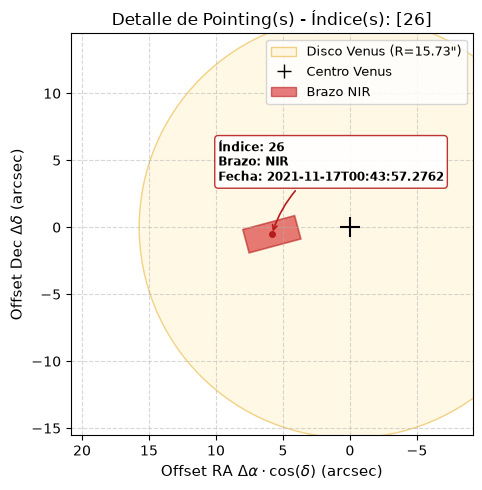

In [ ]:
df_offsets = pd.read_csv('venus_pointings_offsets.txt', sep='\\s+')
# Ejemplo con el indice 26 que está en el 2do pointing
graficar_pointings_individuales(df_offsets,indices=[26], zoom_auto=True) 

# Para graficar cada observation del disco de Venus
#for i in range(df_offsets.shape[0]):
#    graficar_pointings_individuales(df_offsets,i,zoom_auto=True)

# Visualización de los datos reducidos (otro notebook)

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from astropy.io import fits

In [6]:
# Example to open the archive and inspection extensions
with fits.open('1_SCI_IFU_MERGE3D_DATA_OBJ_NIR.fits') as hdul:
    hdul.info()  # Muestra las extensiones (Flujo, Error, Máscara)
    # La primera extensión contiene los datos del cubo 3D
    data_cube = hdul[0].data  # Acceder al data del primer HDU
    header = hdul[0].header  # Acceder al header del primer HDU

print('\nDimensiones del Cubo 3D (NAXIS3 x NAXIS2 x NAXIS1):', data_cube.shape)
print('Wavelength inicial (CRVAL3):', header.get('CRVAL3'))
print('Paso en longitud de onda (CD3_3 o CDELT3):', header.get('CD3_3'))

Filename: 1_SCI_IFU_MERGE3D_DATA_OBJ_NIR.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  FLUX          1 PrimaryHDU     680   (3, 20, 24750)   float32   
  1  ERRS          1 ImageHDU       586   (3, 20, 24750)   float32   
  2  QUAL          1 ImageHDU       586   (3, 20, 24750)   float32   

Dimensiones del Cubo 3D (NAXIS3 x NAXIS2 x NAXIS1): (24750, 20, 3)
Wavelength inicial (CRVAL3): 994.0
Paso en longitud de onda (CD3_3 o CDELT3): 0.0599999986588955


Preprocesamiento (promedié algunos cubos)

In [ ]:
def avg_datacubes(file_path1, file_path2, name_output):
    
    # 1. Abrimos los archivos
    with fits.open(file_path1) as hdul1, fits.open(file_path2) as hdul2:
        
        # Corregido: hdul1 en lugar de hdul
        ext = 0 if hdul1[0].data is not None else 1

        # Esto nos permite cerrar los archivos de forma segura de inmediato.
        data1 = hdul1[ext].data.copy()
        data2 = hdul2[ext].data.copy()
        
        header = hdul1[ext].header.copy()

    if data1.shape != data2.shape:
        raise ValueError("¡Tienen diferentes dimensiones!")

    # Promediamos los arrays ignorando NaNs
    averaged_data = np.nanmean(np.array([data1, data2]), axis=0)

    # Creamos y guardamos el nuevo archivo
    new_hdu = fits.PrimaryHDU(data=averaged_data, header=header)
    new_hdu.writeto(name_output, overwrite=True)
    
    print(f"Nuevo cubo promediado guardado exitosamente como: {name_output}")

In [53]:
avg_datacubes('1_SCI_IFU_MERGE3D_DATA_OBJ_UVB.fits', 
              '1.2_SCI_IFU_MERGE3D_DATA_OBJ_UVB.fits', 
              '1.x_SCI_IFU_MERGE3D_DATA_OBJ_UVB.fits')

Nuevo cubo promediado guardado exitosamente como: 1.x_SCI_IFU_MERGE3D_DATA_OBJ_UVB.fits


In [54]:
avg_datacubes('4_SCI_IFU_MERGE3D_DATA_OBJ_VIS.fits',
              '4.1_SCI_IFU_MERGE3D_DATA_OBJ_VIS.fits',
              '4.x_SCI_IFU_MERGE3D_DATA_OBJ_VIS.fits')

Nuevo cubo promediado guardado exitosamente como: 4.x_SCI_IFU_MERGE3D_DATA_OBJ_VIS.fits


Resta del cielo

In [11]:
def subtract_sky_cube(obj_path, sky_path, output_path):
    """
    Resta un cubo de cielo a un cubo de ciencia y guarda el resultado.
    """

    with fits.open(obj_path) as hdul_obj, fits.open(sky_path) as hdul_sky:
        # Detectar la extensión correcta (0 o 1)
        ext_obj = 0 if hdul_obj[0].data is not None else 1
        ext_sky = 0 if hdul_sky[0].data is not None else 1

        data_obj = hdul_obj[ext_obj].data.copy()
        data_sky = hdul_sky[ext_sky].data.copy()
        header_obj = hdul_obj[ext_obj].header.copy()

    # 2. Verificar compatibilidad geométrica
    if data_obj.shape != data_sky.shape:
        raise ValueError(f"Dimensiones incompatibles: Objeto {data_obj.shape} vs Cielo {data_sky.shape}")

    # 3. Restar el cielo
    data_subtracted = data_obj - data_sky

    # 4. Actualizar metadatos
    sky_filename = os.path.basename(sky_path)
    header_obj['HISTORY'] = f'Sky subtracted using {sky_filename}'

    # 5. Guardar nuevo cubo
    new_hdu = fits.PrimaryHDU(data=data_subtracted, header=header_obj)
    new_hdu.writeto(output_path, overwrite=True)
    
    print(f"Cubo procesado exitosamente: {output_path}")

In [12]:
from astropy.io import fits
import numpy as np
import os

pointings = [1, 2, 3, 4]
arms = ['UVB', 'VIS', 'NIR']

dir = '' 

for pt in pointings:
    for arm in arms:
        # Construir los nombres exactos de los archivos
        obj_file = os.path.join(dir, f'{pt}_SCI_IFU_MERGE3D_DATA_OBJ_{arm}.fits')
        sky_file = os.path.join(dir, f'sky_SCI_IFU_MERGE3D_DATA_OBJ_{arm}.fits')
        out_file = os.path.join(dir, f'{pt}_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_{arm}.fits')
        
        # Verificar que tanto el archivo de objeto como el de cielo existan
        if os.path.exists(obj_file) and os.path.exists(sky_file):
            print(f"Procesando Pointing {pt} - Brazo {arm}...")
            subtract_sky_cube(obj_file, sky_file, out_file)
        else:
            print(f"Omitiendo Pointing {pt} - Brazo {arm} (Archivos no encontrados)")

print("\n¡Limpieza de cielo completada para todos los cubos disponibles!")

Procesando Pointing 1 - Brazo UVB...
Cubo procesado exitosamente: 1_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_UVB.fits
Procesando Pointing 1 - Brazo VIS...
Cubo procesado exitosamente: 1_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_VIS.fits
Procesando Pointing 1 - Brazo NIR...
Cubo procesado exitosamente: 1_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_NIR.fits
Procesando Pointing 2 - Brazo UVB...
Cubo procesado exitosamente: 2_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_UVB.fits
Procesando Pointing 2 - Brazo VIS...
Cubo procesado exitosamente: 2_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_VIS.fits
Procesando Pointing 2 - Brazo NIR...
Cubo procesado exitosamente: 2_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_NIR.fits
Procesando Pointing 3 - Brazo UVB...
Cubo procesado exitosamente: 3_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_UVB.fits
Procesando Pointing 3 - Brazo VIS...
Cubo procesado exitosamente: 3_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_VIS.fits
Procesando Pointing 3 - Brazo NIR...
Cubo procesado exitosamente: 3_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_NIR.fits
Procesando Pointing

## Ahora si, visualización de los datos reducidos y restados de cielo

C:\Users\fmoll\AppData\Local\Temp\ipykernel_12496\1932079635.py:58: RuntimeWarning: invalid value encountered in log10
  spec_plot = np.where(spectrum_1d > 0, np.log10(spectrum_1d), np.nan)


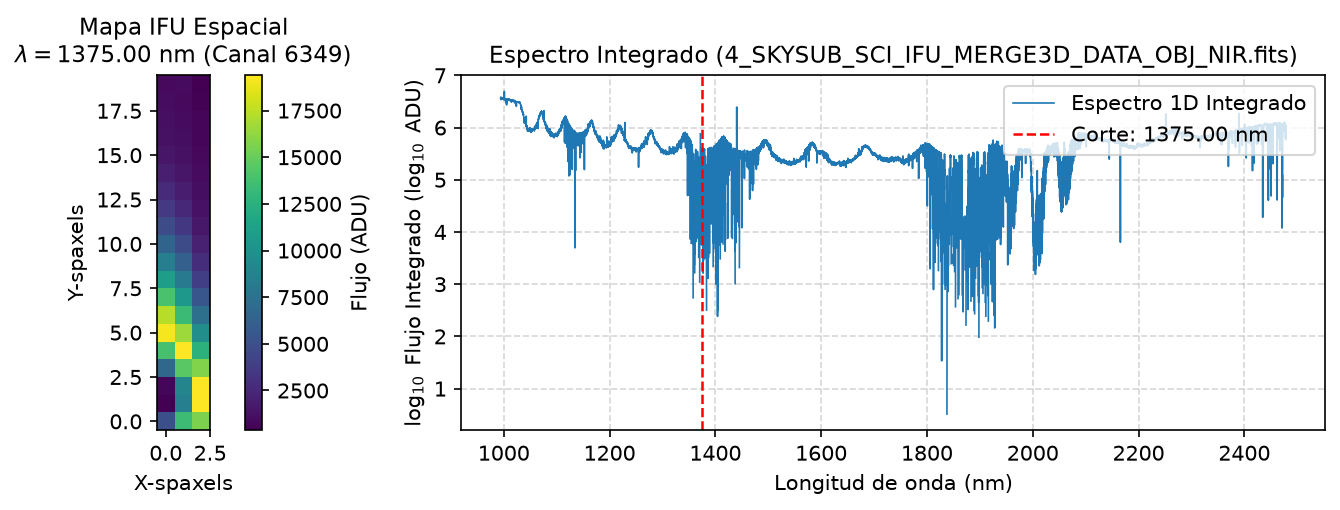

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from astropy.io import fits

def plot_summary(fits_path, target_wave=None, log_scale=True, save_path=None):
    """
    Genera un panel doble de diagnóstico a partir de un archivo FITS:
    - Izquierda: Mapa espacial 2D en la longitud de onda seleccionada.
    - Derecha: Espectro 1D integrado con una línea marcadora.
    """
    filename = os.path.basename(fits_path)
    
    # 1. Cargar datos y header
    with fits.open(fits_path) as hdul:
        ext = 0 if hdul[0].data is not None else 1
        data_cube = hdul[ext].data.astype(np.float32)
        header = hdul[ext].header

    n_wave, n_y, n_x = data_cube.shape

    # 2. Reconstruir eje de longitud de onda
    crval3 = float(header.get('CRVAL3', 0.0))
    cdelt3 = float(header.get('CDELT3', header.get('CD3_3', 1.0)))
    crpix3 = float(header.get('CRPIX3', 1.0))

    pixels = np.arange(n_wave)
    wavelengths = crval3 + (pixels - (crpix3 - 1.0)) * cdelt3

    # 3. Determinar el canal y la longitud de onda real a graficar
    if target_wave is None:
        channel = n_wave // 2
    else:
        channel = int(round((target_wave - crval3) / cdelt3 + (crpix3 - 1.0)))
        channel = int(np.clip(channel, 0, n_wave - 1))
        
    actual_wave = float(wavelengths[channel])

    # 4. Extraer el mapa espacial y calcular el espectro integrado
    spatial_map = data_cube[channel, :, :]
    spectrum_1d = np.nansum(data_cube, axis=(1, 2))

    # 5. Generar la figura
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.5), dpi=150)

    # --- Izquierda: Mapa Espacial ---
    vmin = np.nanpercentile(spatial_map, 2)
    vmax = np.nanpercentile(spatial_map, 98)
    im = ax1.imshow(spatial_map, origin='lower', cmap='viridis', vmin=vmin, vmax=vmax)
    ax1.set_title(f'Mapa IFU Espacial\n$\\lambda = {actual_wave:.2f}$ nm (Canal {channel})', fontsize=11)
    ax1.set_xlabel('X-spaxels')
    ax1.set_ylabel('Y-spaxels')
    fig.colorbar(im, ax=ax1, label='Flujo (ADU)', fraction=0.046, pad=0.04)

    # --- Derecha: Espectro 1D Integrado ---
    if log_scale:
        spec_plot = np.where(spectrum_1d > 0, np.log10(spectrum_1d), np.nan)
        ylabel = '$\\log_{10}$ Flujo Integrado ($\\log_{10}$ ADU)'
    else:
        spec_plot = spectrum_1d
        ylabel = 'Flujo Integrado (ADU)'

    ax2.plot(wavelengths, spec_plot, color='#1f77b4', lw=0.8, label='Espectro 1D Integrado')
    ax2.axvline(x=actual_wave, color='red', linestyle='--', lw=1.2, label=f'Corte: {actual_wave:.2f} nm')
    ax2.set_title(f'Espectro Integrado ({filename})', fontsize=11)
    ax2.set_xlabel('Longitud de onda (nm)')
    ax2.set_ylabel(ylabel)
    ax2.grid(True, linestyle='--', alpha=0.5)
    ax2.legend(loc='upper right')

    plt.tight_layout()

    # 6. Guardar o mostrar
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Gráfico guardado en: {save_path}")
    plt.show()

# Ejemplo
plot_summary('4_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_NIR.fits', target_wave=1375)

Función generadora de gifs de los espectros

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from astropy.io import fits

def crear_gif_interactivo(fits_file, output_gif='animacion_venus.gif', step=150, fps=15):
    """
    Genera un GIF con dos paneles: 
    Arriba: Mapa espacial 2D animado.
    Abajo: Espectro 1D integrado con una línea vertical indicando la longitud de onda actual.
    
    step: Salto entre canales. Un cubo NIR tiene ~25000 canales. 
    """
    
    # 1. Cargar datos
    with fits.open(fits_file) as hdul:
        ext = 0 if hdul[0].data is not None else 1
        data = hdul[ext].data
        header = hdul[ext].header
        
    n_wave, n_y, n_x = data.shape
    
    # 2. Reconstruir eje de longitud de onda
    crval3 = header['CRVAL3']
    cdelt3 = header.get('CDELT3', header.get('CD3_3'))
    crpix3 = header.get('CRPIX3', 1.0)
    wavelengths = crval3 + (np.arange(n_wave) - (crpix3 - 1)) * cdelt3
    
    # 3. Calcular espectro 1D integrado (para el panel inferior)
    spec_1d = np.nansum(data, axis=(1, 2))
    
    # 4. Configurar la figura y los dos paneles
    fig, (ax_map, ax_spec) = plt.subplots(2, 1, figsize=(7, 8), gridspec_kw={'height_ratios': [1.5, 1]})
    
    # --- PANEL SUPERIOR: MAPA ESPACIAL ---
    vmin, vmax = np.nanpercentile(data, 2), np.nanpercentile(data, 98)
    
    im = ax_map.imshow(data[0, :, :], origin='lower', cmap='viridis', vmin=vmin, vmax=vmax)
    cbar = fig.colorbar(im, ax=ax_map, pad=0.02)
    cbar.set_label('Flujo (ADU)')
    title = ax_map.set_title(f'Mapa Espacial - $\\lambda = {wavelengths[0]:.2f}$ nm')
    ax_map.set_xlabel('X-spaxels')
    ax_map.set_ylabel('Y-spaxels')
    
    # --- PANEL INFERIOR: ESPECTRO 1D ---
    # Graficamos todo el espectro de fondo
    spec_log = np.where(spec_1d > 0, np.log10(spec_1d), np.nan)
    ax_spec.plot(wavelengths, spec_log, color='black', lw=0.8)
    ax_spec.set_xlim(wavelengths[0], wavelengths[-1])
    ax_spec.set_xlabel('Longitud de Onda (nm)')
    ax_spec.set_ylabel('Log Flujo Integrado (log10 ADU)')
    ax_spec.grid(True, linestyle='--', alpha=0.5)
    
    # La línea roja vertical que se moverá
    vline = ax_spec.axvline(x=wavelengths[0], color='red', lw=2, alpha=0.8)
    
    plt.tight_layout()
    
    # 5. Función de actualización para la animación
    # Usamos list(range) para precalcular los índices exactos según el 'step'
    frames = list(range(0, n_wave, step))
    
    def update(idx):
        ch = frames[idx]
        wave = wavelengths[ch]
        
        # Actualizar imagen 2D
        im.set_data(data[ch, :, :])
        title.set_text(f'Mapa Espacial - $\\lambda = {wave:.2f}$ nm')
        
        # Actualizar posición de la barra indicadora en el espectro
        vline.set_xdata([wave, wave])
        
        return [im, title, vline]
    
    # 6. Crear y guardar la animación
    ani = animation.FuncAnimation(fig, update, frames=len(frames), blit=True, interval=1000//fps)
    
    ani.save(output_gif, writer='pillow', fps=fps)
    plt.close(fig)
    print(f"¡GIF guardado exitosamente como {output_gif}!")


In [12]:
import os

pointings = [1, 2, 3, 4]
arms = ['UVB', 'VIS', 'NIR']
directorio = ''

for pt in pointings:
    for arm in arms:
        # Construir el nombre del archivo de entrada según tu nueva nomenclatura
        fits_file = os.path.join(directorio, f'{pt}_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_{arm}.fits')
        
        # Construir el nombre del archivo GIF de salida
        output_gif = os.path.join('gifs_espectros', f'venus_{pt}_{arm}.gif')
        
        # Verificar que el archivo FITS exista antes de procesarlo
        if os.path.exists(fits_file):
            print(f"\n--- Iniciando Pointing {pt} - Brazo {arm} ---")
            try:
                paso = 150 if arm == 'NIR' else 100
                
                crear_gif_interactivo(fits_file, output_gif=output_gif, step=paso, fps=15)
            except Exception as e:
                print(f"Error al procesar {fits_file}: {e}")
        else:
            print(f"Omitiendo: {fits_file} (Archivo no encontrado)")

print("\n¡Automatización de GIFs completada para todos los archivos!")


--- Iniciando Pointing 1 - Brazo UVB ---


C:\Users\fmoll\AppData\Local\Temp\ipykernel_12496\1341861137.py:47: RuntimeWarning: invalid value encountered in log10
  spec_log = np.where(spec_1d > 0, np.log10(spec_1d), np.nan)


¡GIF guardado exitosamente como gifs_espectros\venus_1_UVB.gif!

--- Iniciando Pointing 1 - Brazo VIS ---


C:\Users\fmoll\AppData\Local\Temp\ipykernel_12496\1341861137.py:47: RuntimeWarning: invalid value encountered in log10
  spec_log = np.where(spec_1d > 0, np.log10(spec_1d), np.nan)


¡GIF guardado exitosamente como gifs_espectros\venus_1_VIS.gif!

--- Iniciando Pointing 1 - Brazo NIR ---


C:\Users\fmoll\AppData\Local\Temp\ipykernel_12496\1341861137.py:47: RuntimeWarning: invalid value encountered in log10
  spec_log = np.where(spec_1d > 0, np.log10(spec_1d), np.nan)


... (13 outputs left out)

C:\Users\fmoll\AppData\Local\Temp\ipykernel_12496\1341861137.py:47: RuntimeWarning: invalid value encountered in log10
  spec_log = np.where(spec_1d > 0, np.log10(spec_1d), np.nan)


¡GIF guardado exitosamente como gifs_espectros\venus_4_VIS.gif!

--- Iniciando Pointing 4 - Brazo NIR ---


C:\Users\fmoll\AppData\Local\Temp\ipykernel_12496\1341861137.py:47: RuntimeWarning: invalid value encountered in log10
  spec_log = np.where(spec_1d > 0, np.log10(spec_1d), np.nan)


¡GIF guardado exitosamente como gifs_espectros\venus_4_NIR.gif!

¡Automatización de GIFs completada para todos los archivos!


## Revisión de los espectros IFU

In [21]:
import numpy as np
from astropy.io import fits
import os

def normalize_spaxels(fits_file, output_file):
    """
    Normaliza cada spaxel de un cubo IFU dividiendo su espectro por la mediana de su propio flujo.
    """
    with fits.open(fits_file) as hdul:
        ext = 0 if hdul[0].data is not None else 1
        data = hdul[ext].data.copy()
        header = hdul[ext].header.copy()

    # 1. Calcular el mapa espacial de medianas (colapsando el eje 0: longitud de onda)
    median_map = np.nanmedian(data, axis=0)

    # 2. Prevenir divisiones por cero (spaxels vacíos en los bordes del IFU) y reemplazamos los ceros por 1 
    # temporalmente en el denominador
    denominador = np.where(median_map == 0, 1, median_map)

    # 3. Normalizamos el mapa 2D correspondiente (dimensiones 1 y 2).
    normalized_data = data / denominador

    # 4. Restaurar los pixeles vacíos/malos originales (donde la mediana era 0 o NaN)
    normalized_data = np.where((median_map == 0) | np.isnan(median_map), np.nan, normalized_data)

    # 5. Guardar el nuevo cubo normalizado
    header['HISTORY'] = 'Spaxels normalized by their spectral median flux'
    new_hdu = fits.PrimaryHDU(data=normalized_data, header=header)
    new_hdu.writeto(output_file, overwrite=True)

# Para todos los archivos
pointings = [1, 2, 3, 4]
arms = ['UVB', 'VIS', 'NIR']
directorio = '' 

for pt in pointings:
    for arm in arms:
        # Usamos los archivos que generaste en el paso anterior
        input_file = os.path.join(directorio, f'{pt}_SKYSUB_SCI_IFU_MERGE3D_DATA_OBJ_{arm}.fits')
        out_file = os.path.join('dcs_normalized', f'{pt}_NORM_SKYSUB_{arm}.fits')
        
        if os.path.exists(input_file):
            print(f"Normalizando Pointing {pt} - Brazo {arm}...")
            try:
                normalize_spaxels(input_file, out_file)
            except Exception as e:
                print(f"❌ Error al procesar {input_file}: {e}")
        else:
            print(f"Omitiendo: {input_file} (No encontrado)")

print("\n¡Normalización completada!")

Normalizando Pointing 1 - Brazo UVB...
Normalizando Pointing 1 - Brazo VIS...
Normalizando Pointing 1 - Brazo NIR...
Normalizando Pointing 2 - Brazo UVB...
Normalizando Pointing 2 - Brazo VIS...
Normalizando Pointing 2 - Brazo NIR...
Normalizando Pointing 3 - Brazo UVB...
Normalizando Pointing 3 - Brazo VIS...
Normalizando Pointing 3 - Brazo NIR...
Normalizando Pointing 4 - Brazo UVB...
Normalizando Pointing 4 - Brazo VIS...
Normalizando Pointing 4 - Brazo NIR...

¡Normalización completada!


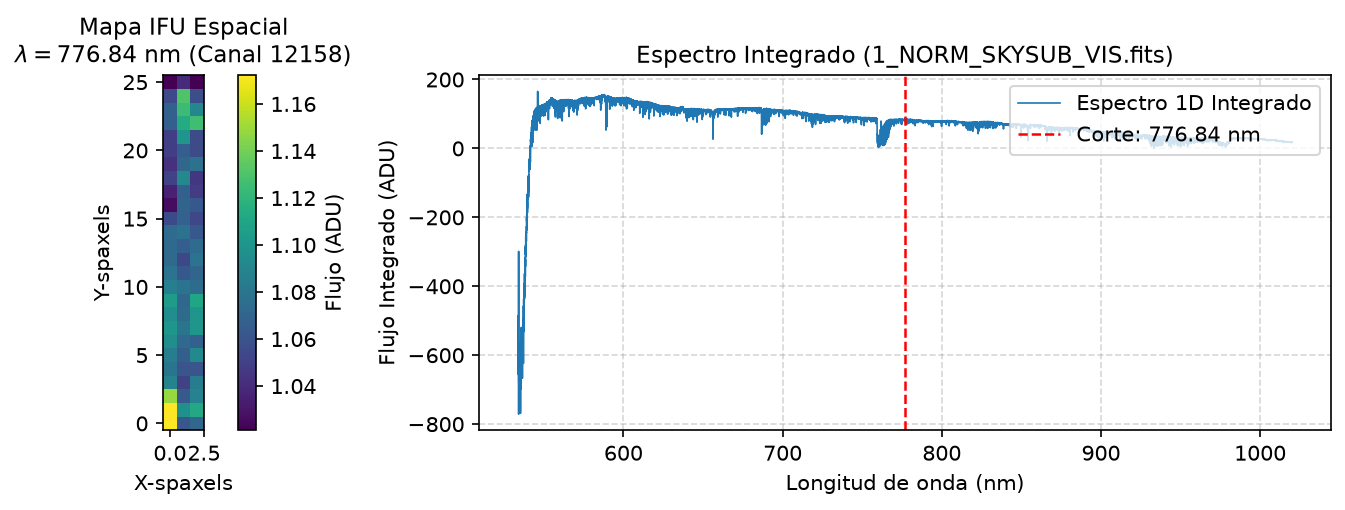

In [33]:
plot_summary('dcs_normalized\\1_NORM_SKYSUB_VIS.fits', log_scale=False, save_path=None)

Veamos los Mapa IFU espacial, donde veremos el promedio y desviación estandar de cada spaxel. Hay que colapsar el eje de longitud de onda.

In [5]:
import numpy as np
from astropy.io import fits
import os
import matplotlib.pyplot as plt

def colapso_ifu(fits_file):
    """

    """
    with fits.open(fits_file) as hdul:
        ext = 0 if hdul[0].data is not None else 1
        data = hdul[ext].data

    # calculamos mean y std colapsando el eje 0
    mean_map = np.nanmean(data, axis=0)
    std_map = np.nanstd(data, axis=0)

    # Gráfico
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), dpi=120)
    
    # Mapa de Promedio
    im1 = ax1.imshow(mean_map, origin='lower', cmap='viridis')
    ax1.set_title('Mapa 2D: Promedio por Spaxel')
    ax1.set_xlabel('X-spaxels')
    ax1.set_ylabel('Y-spaxels')
    fig.colorbar(im1, ax=ax1, label='Promedio')
    
    # Mapa de Desviación Estándar
    # Usamos vmax con el percentil 95 para que un solo pixel roto no arruine la escala de color
    vmax_std = np.nanpercentile(std_map, 95)
    im2 = ax2.imshow(std_map, origin='lower', cmap='viridis', vmax=vmax_std)
    ax2.set_title('Mapa 2D: Desviación Estándar por Spaxel')
    ax2.set_xlabel('X-spaxels')
    ax2.set_ylabel('Y-spaxels')
    fig.colorbar(im2, ax=ax2, label='Desviación Estándar')
    
    plt.suptitle(f'Colapso IFU: {fits_file}', y=1.05, fontweight='bold')
    plt.tight_layout()
    plt.show()


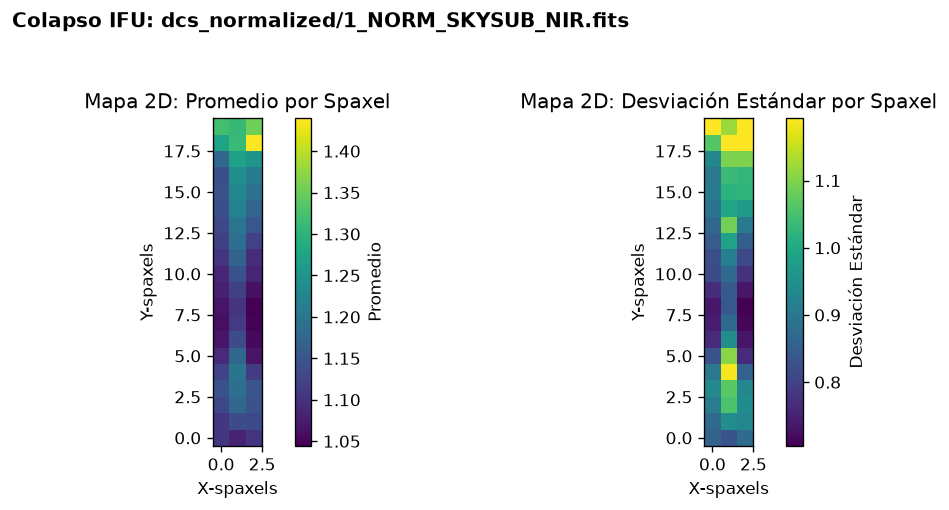

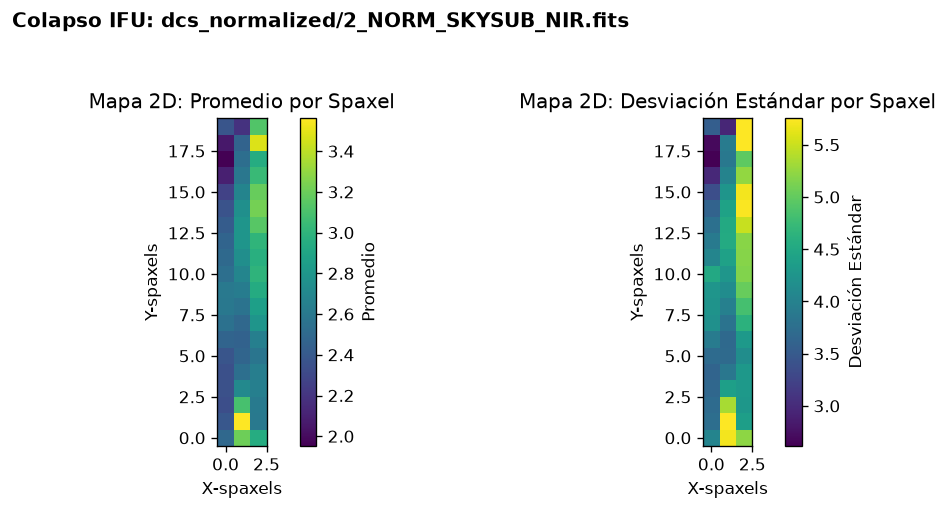

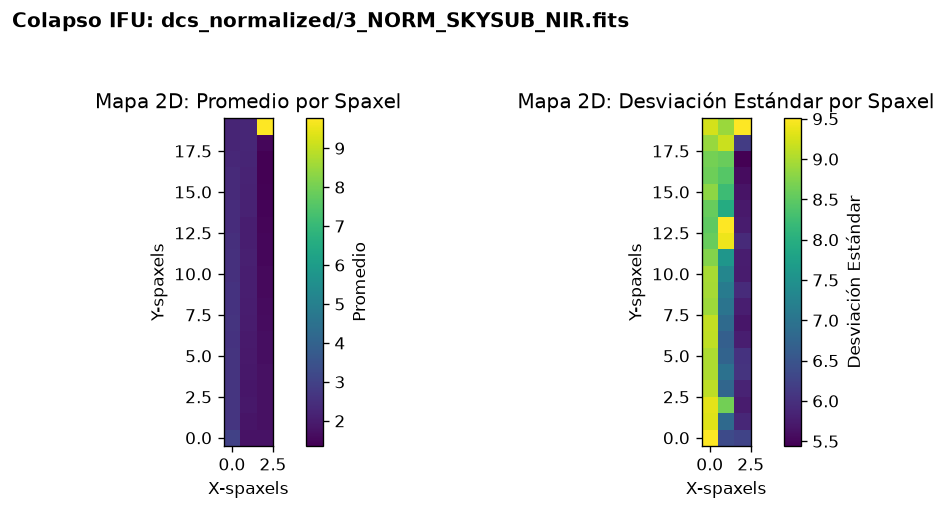

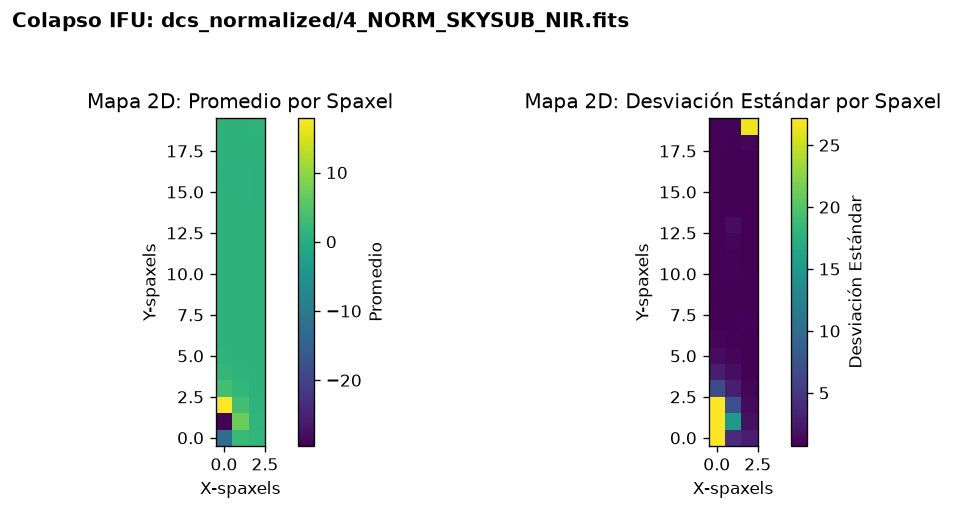

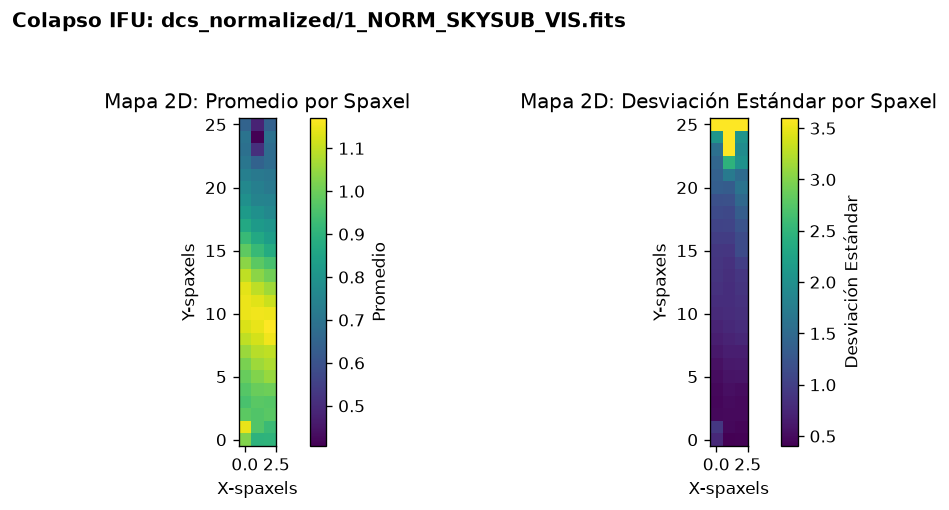

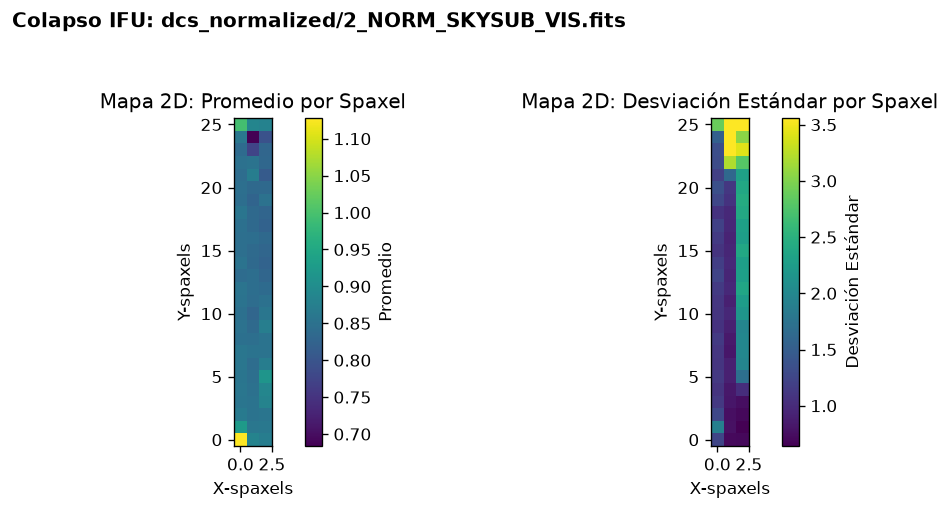

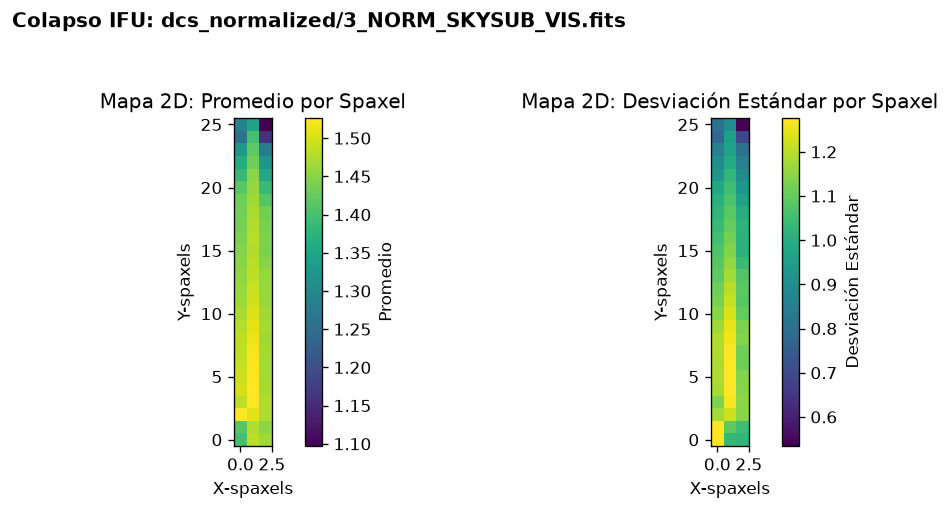

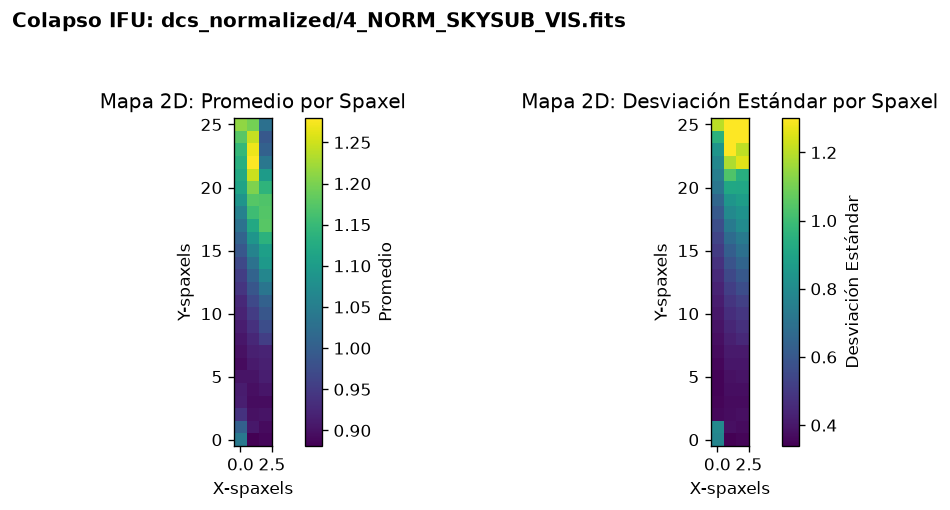

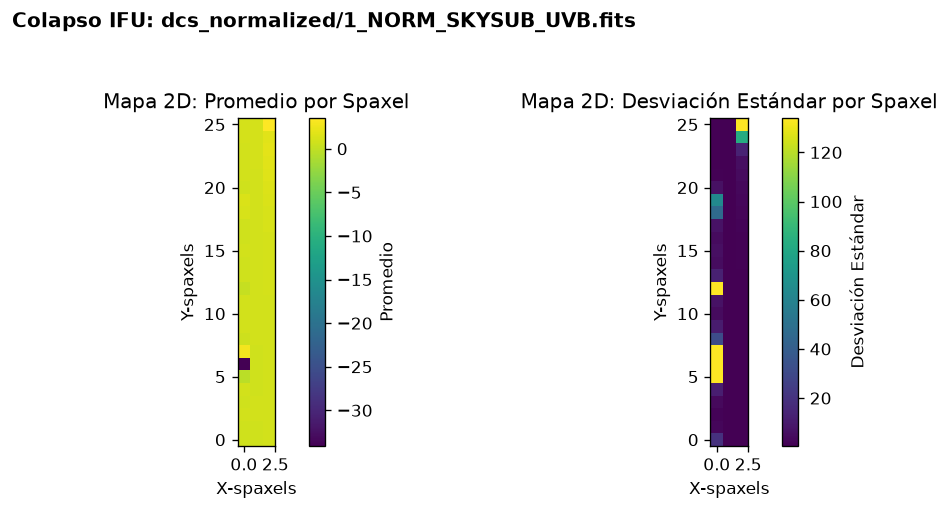

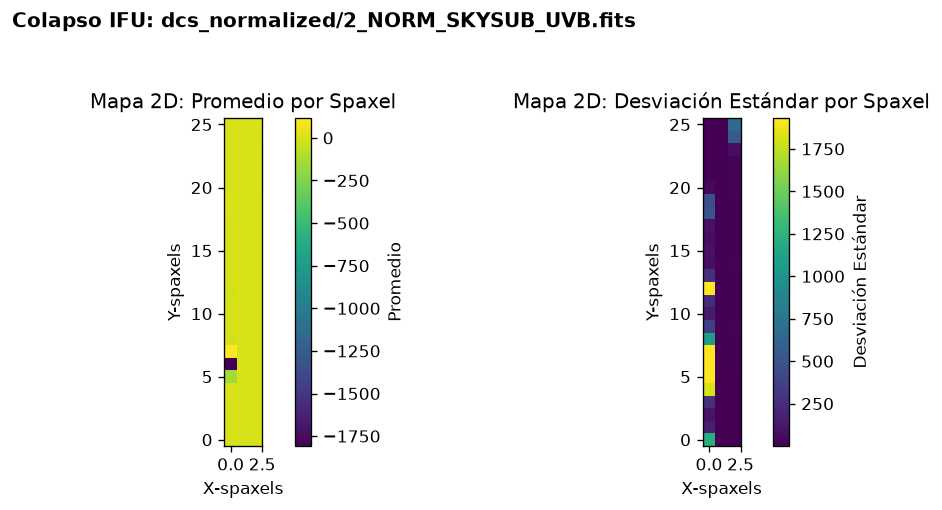

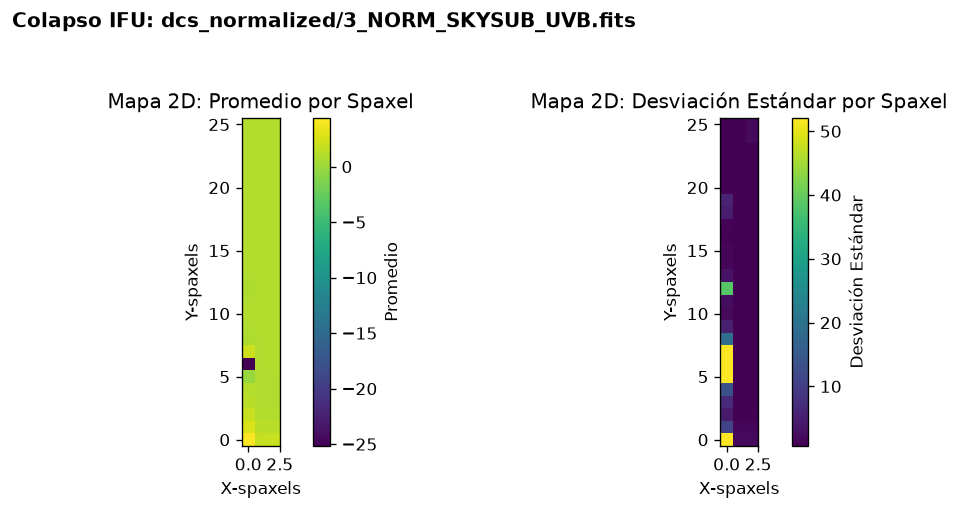

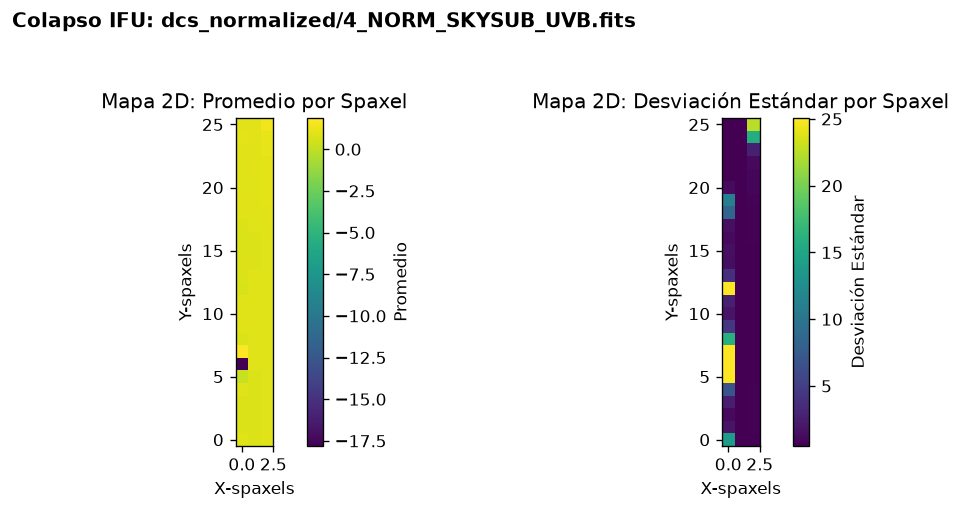

In [6]:
pointings = [1, 2, 3, 4]
arms = ['NIR', 'VIS', 'UVB']
carpeta = 'dcs_normalized'

for arm in arms:
    for pt in pointings:
        # Construcción correcta del f-string con la ruta
        archivo_fits = f"{carpeta}/{pt}_NORM_SKYSUB_{arm}.fits"
        colapso_ifu(archivo_fits) 

Mapa 3d de mean y std de cada spaxel

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import os

def graficar_mapa_3d(fits_file):
    """
    Genera gráficos de superficie 3D para el IFU para promedio y desviación estandar
    """
    # 1. Cargar los datos
    with fits.open(fits_file) as hdul:
        ext = 0 if hdul[0].data is not None else 1
        data = hdul[ext].data
        
    # 2. Calcular el mapa 2D colapsando el eje espectral
    mapa_promedio = np.nanmean(data, axis=0)
    mapa_std = np.nanstd(data, axis=0)
        
    # 3. Construir la cuadrícula espacial
    ny, nx = mapa_promedio.shape
    x = np.arange(nx)
    y = np.arange(ny)
    X, Y = np.meshgrid(x, y)
    
    # 4. Configurar la figura para 2 paneles 3D
    fig = plt.figure(figsize=(15, 7), dpi=120)
    
    # --- PANEL 1: PROMEDIO ---
    ax1 = fig.add_subplot(121, projection='3d')
    surf1 = ax1.plot_surface(X, Y, mapa_promedio, cmap='viridis', edgecolor='k', 
                             linewidth=0.5, alpha=0.9, rstride=1, cstride=1)
    
    ax1.set_xlim(-0.5, 2.5)
    ax1.set_ylim(0, 25)
    ax1.set_title('Flujo Promedio (Normalizado)')
    ax1.set_xlabel('Eje X (Spaxels)')
    ax1.set_ylabel('Eje Y (Spaxels)')
    ax1.set_zlabel('Promedio')
    ax1.view_init(elev=30, azim=45)
    fig.colorbar(surf1, ax=ax1, shrink=0.5, aspect=10, pad=0.1, label='Promedio')
    
    # --- PANEL 2: DESVIACIÓN ESTÁNDAR ---
    ax2 = fig.add_subplot(122, projection='3d')
    surf2 = ax2.plot_surface(X, Y, mapa_std, cmap='viridis', edgecolor='k', 
                             linewidth=0.5, alpha=0.9, rstride=1, cstride=1)
    
    ax2.set_xlim(-0.5, 2.5)
    ax2.set_ylim(0, 25)
    ax2.set_title('Desviación Estándar (Ruido)')
    ax2.set_xlabel('Eje X (Spaxels)')
    ax2.set_ylabel('Eje Y (Spaxels)')
    ax2.set_zlabel('Std')
    ax2.view_init(elev=30, azim=45)
    fig.colorbar(surf2, ax=ax2, shrink=0.5, aspect=10, pad=0.1, label='Std')
    
    # Formato general
    plt.suptitle(f'Diagnóstico 3D IFU: {fits_file}', fontsize=14, fontweight='bold', y=0.95)
    plt.tight_layout()
    plt.show()

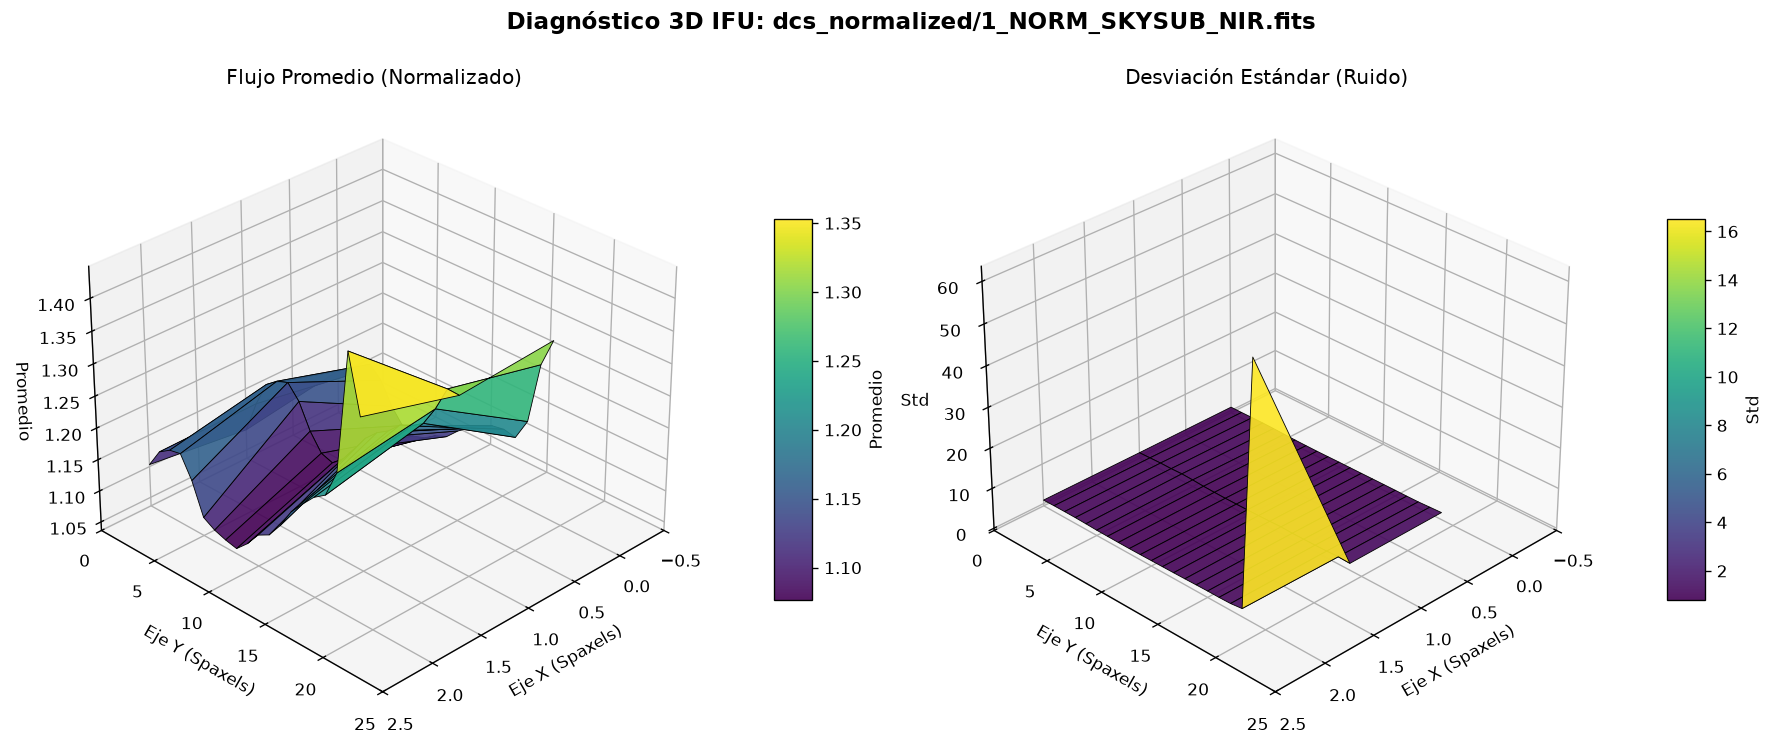

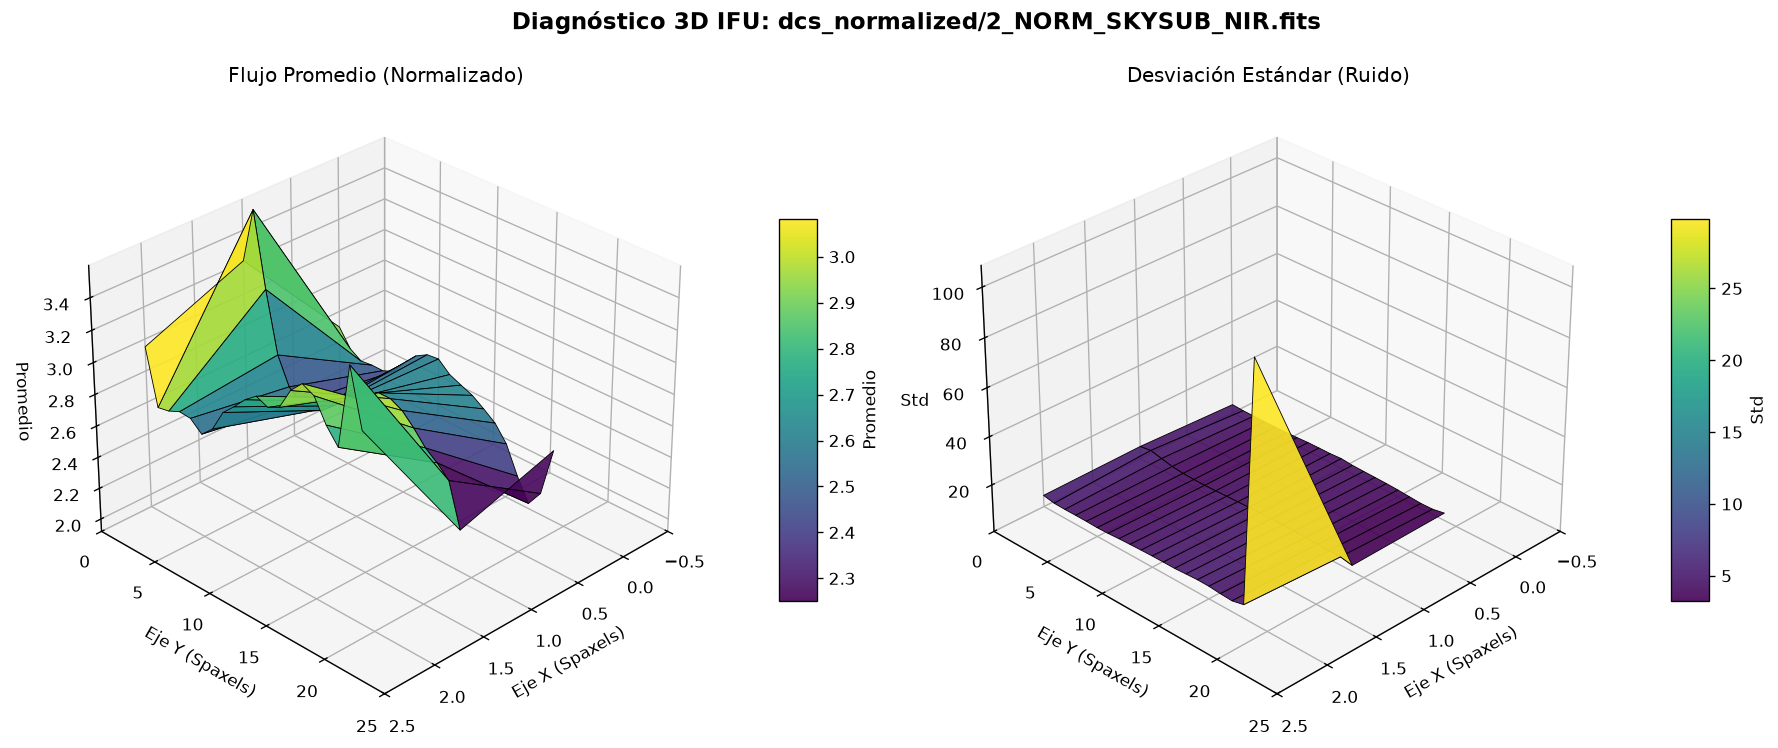

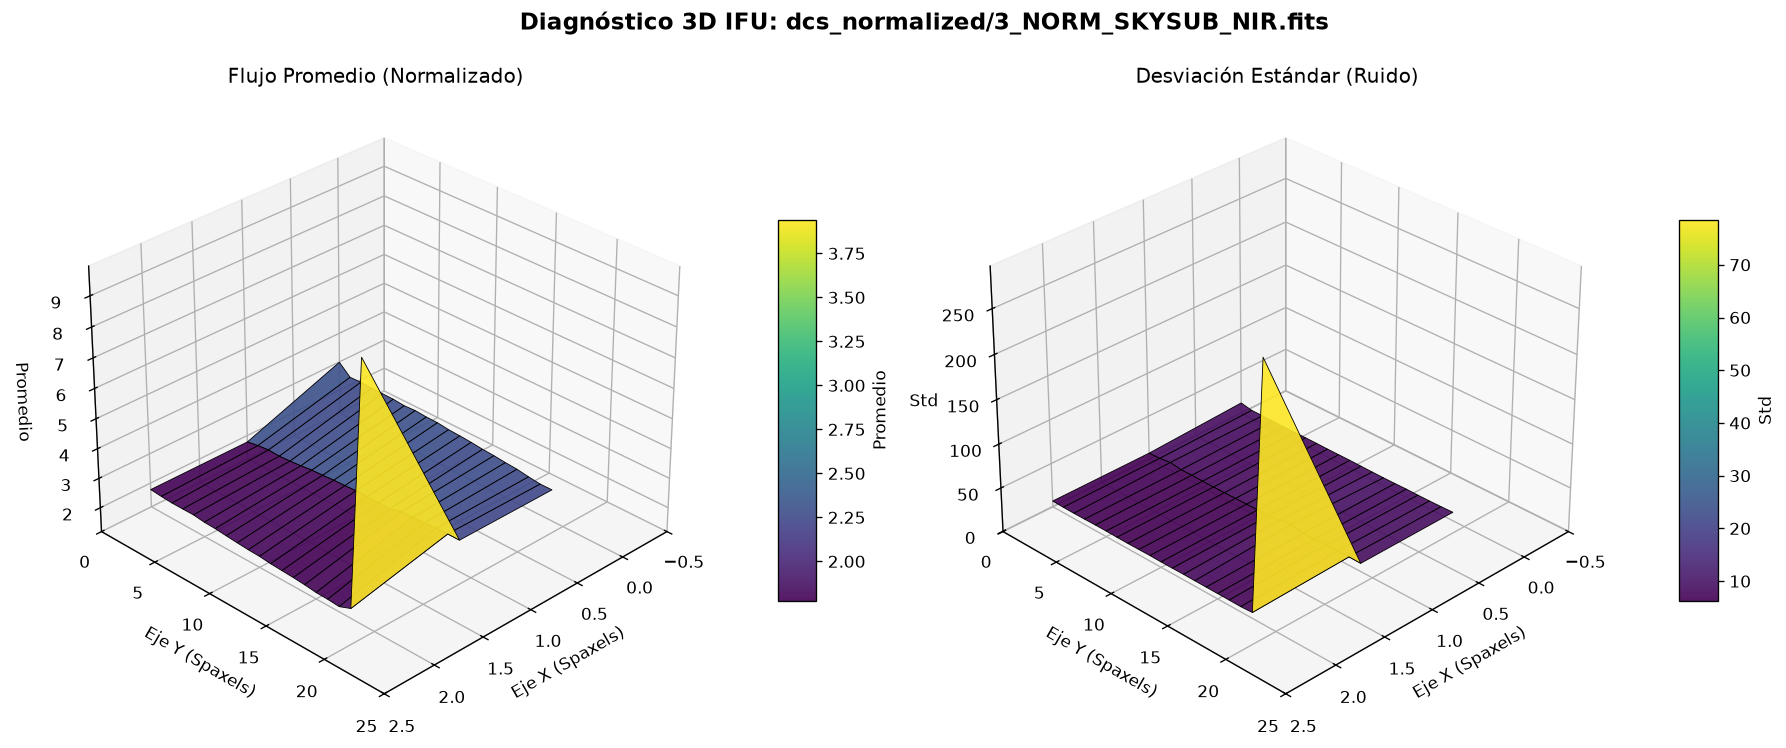

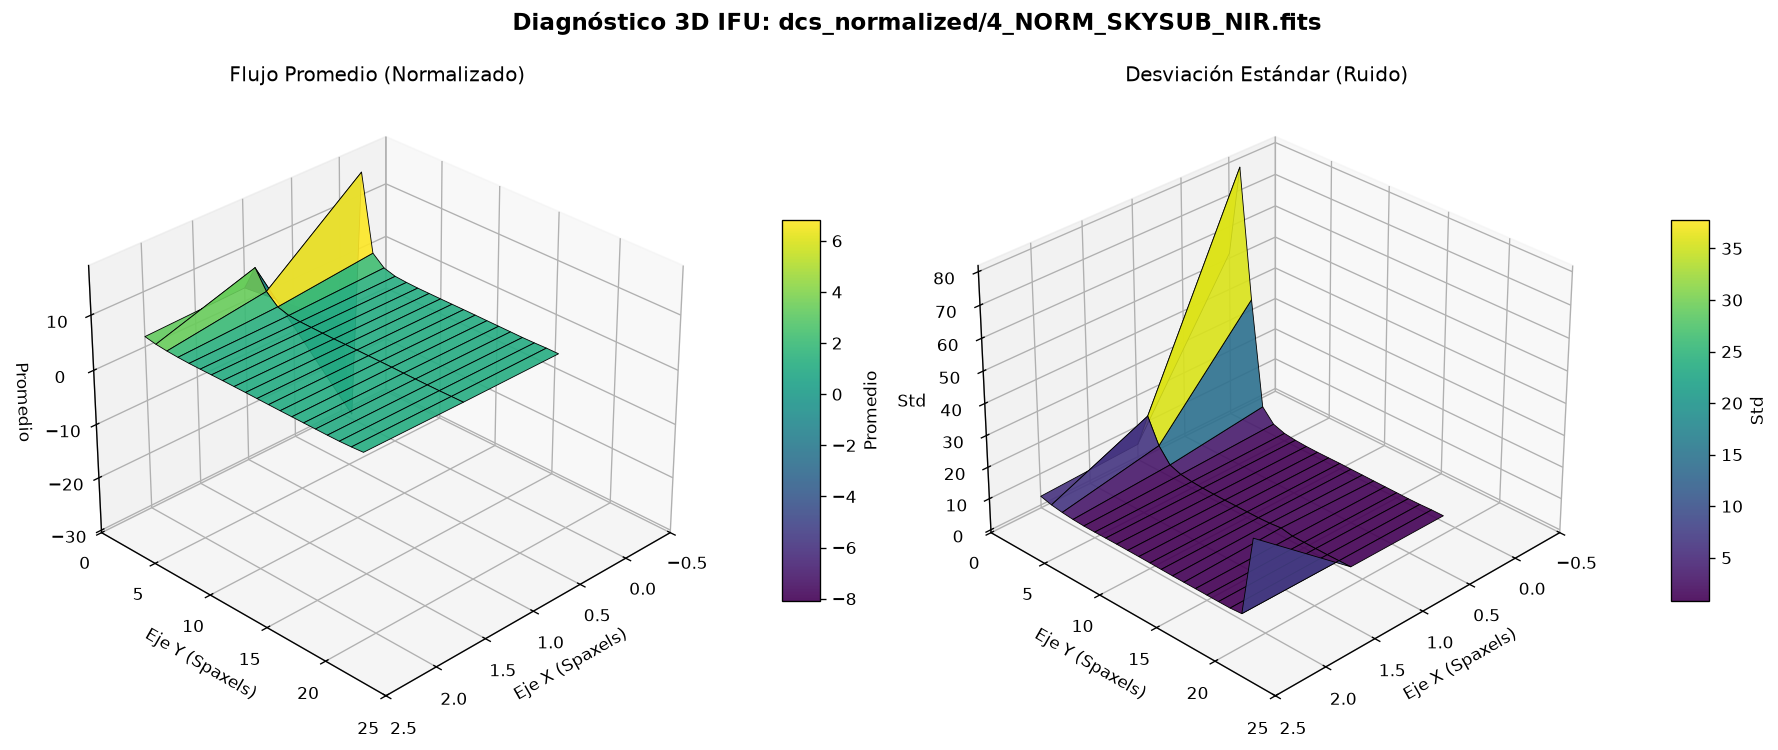

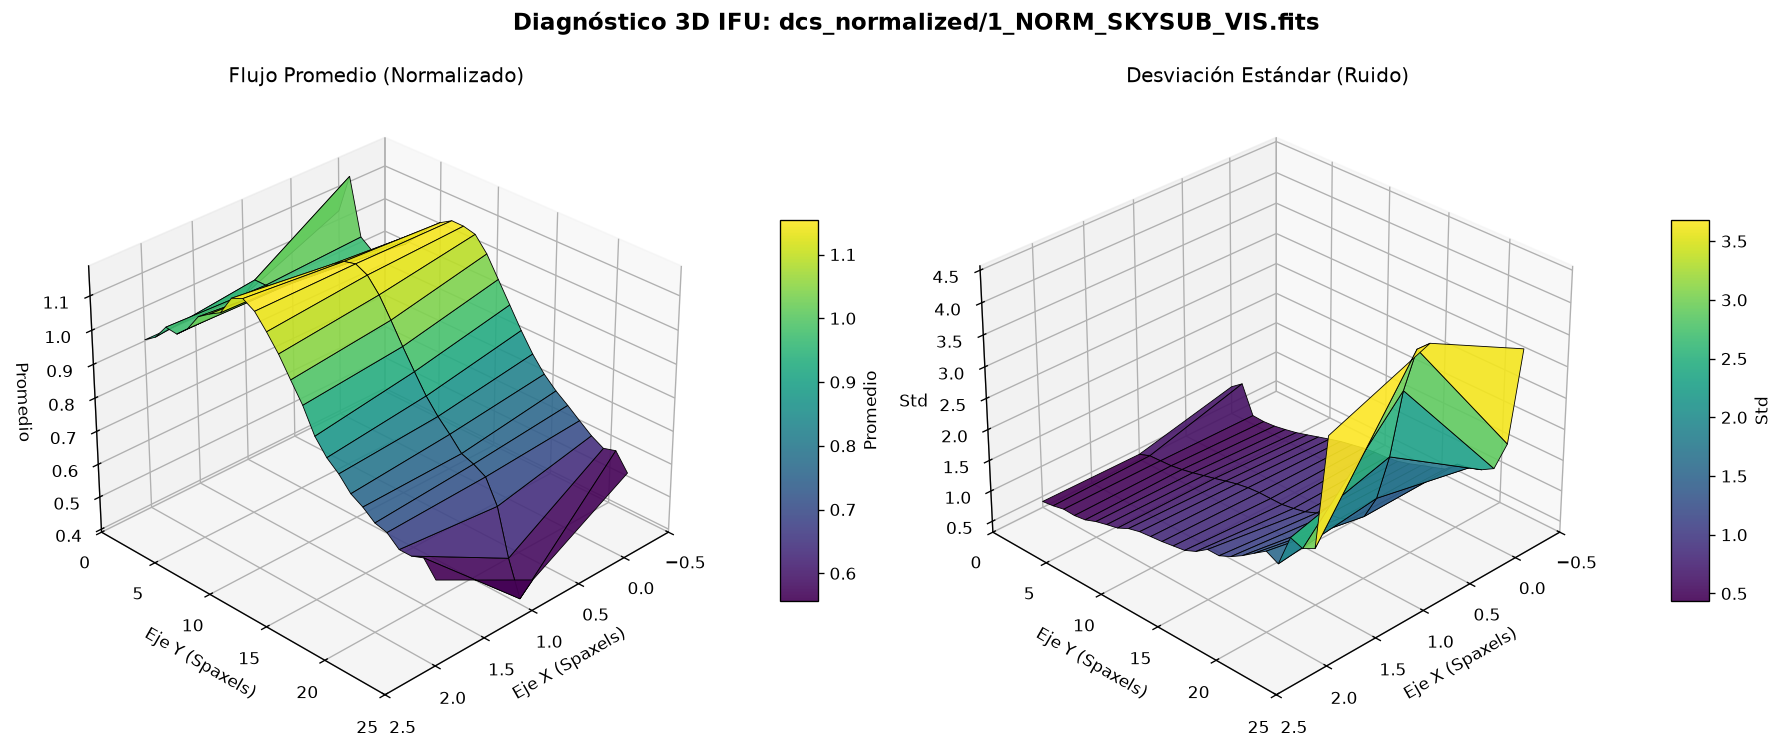

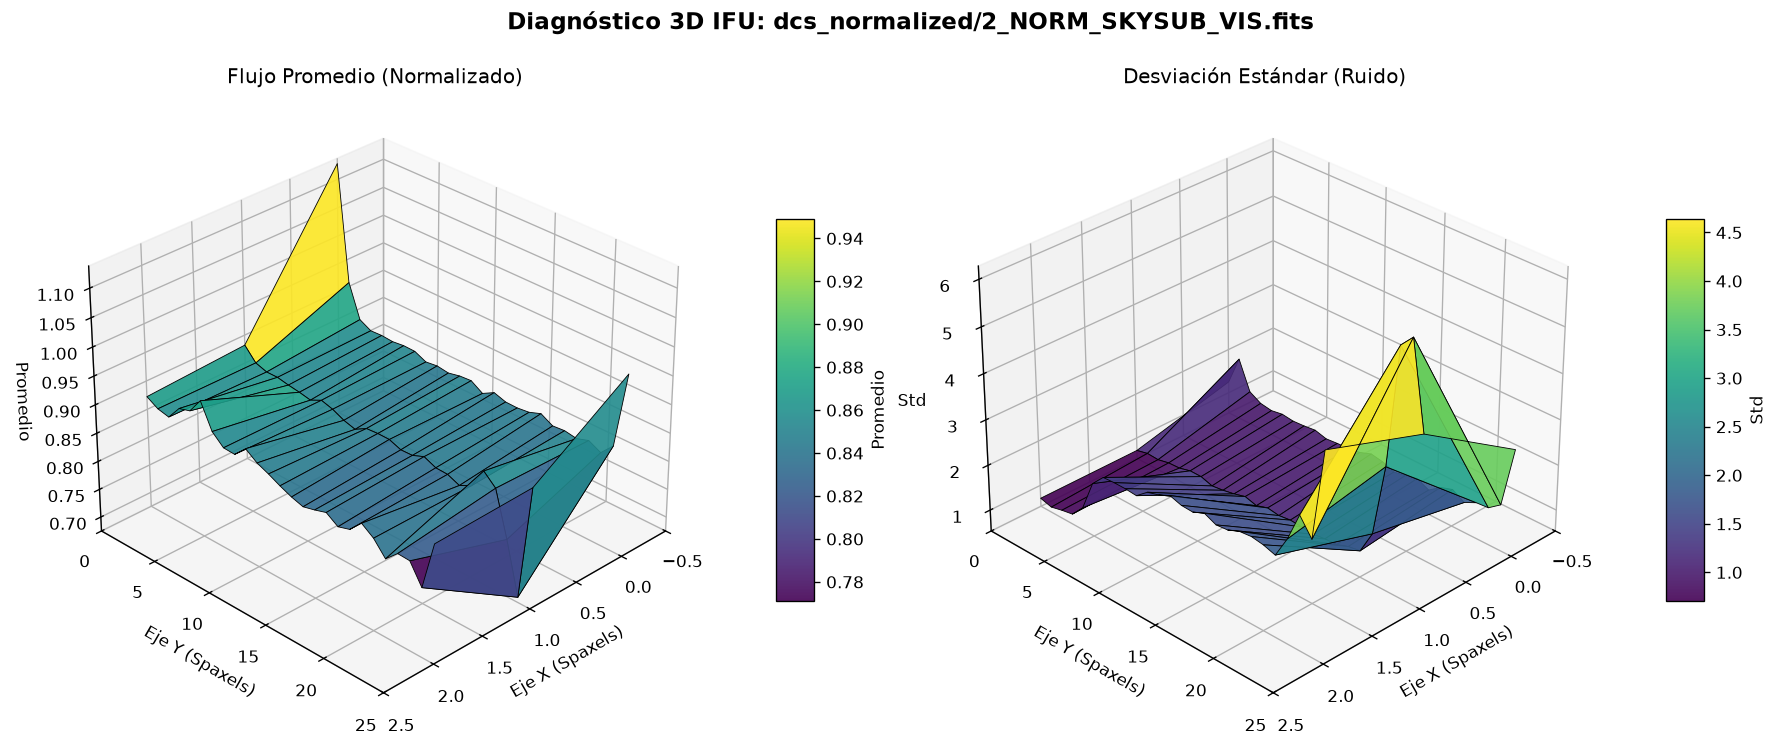

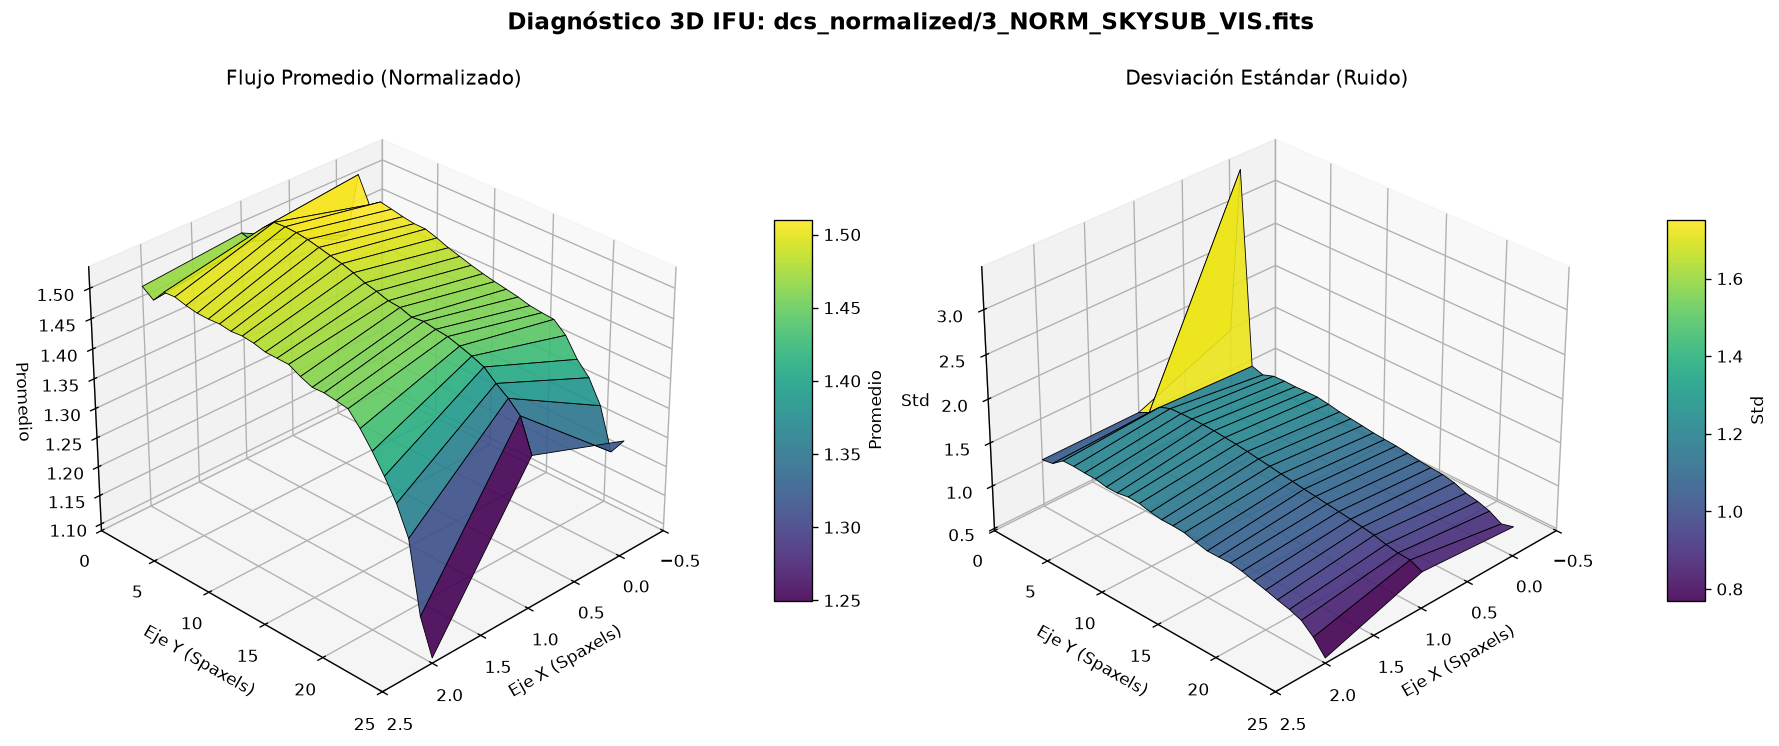

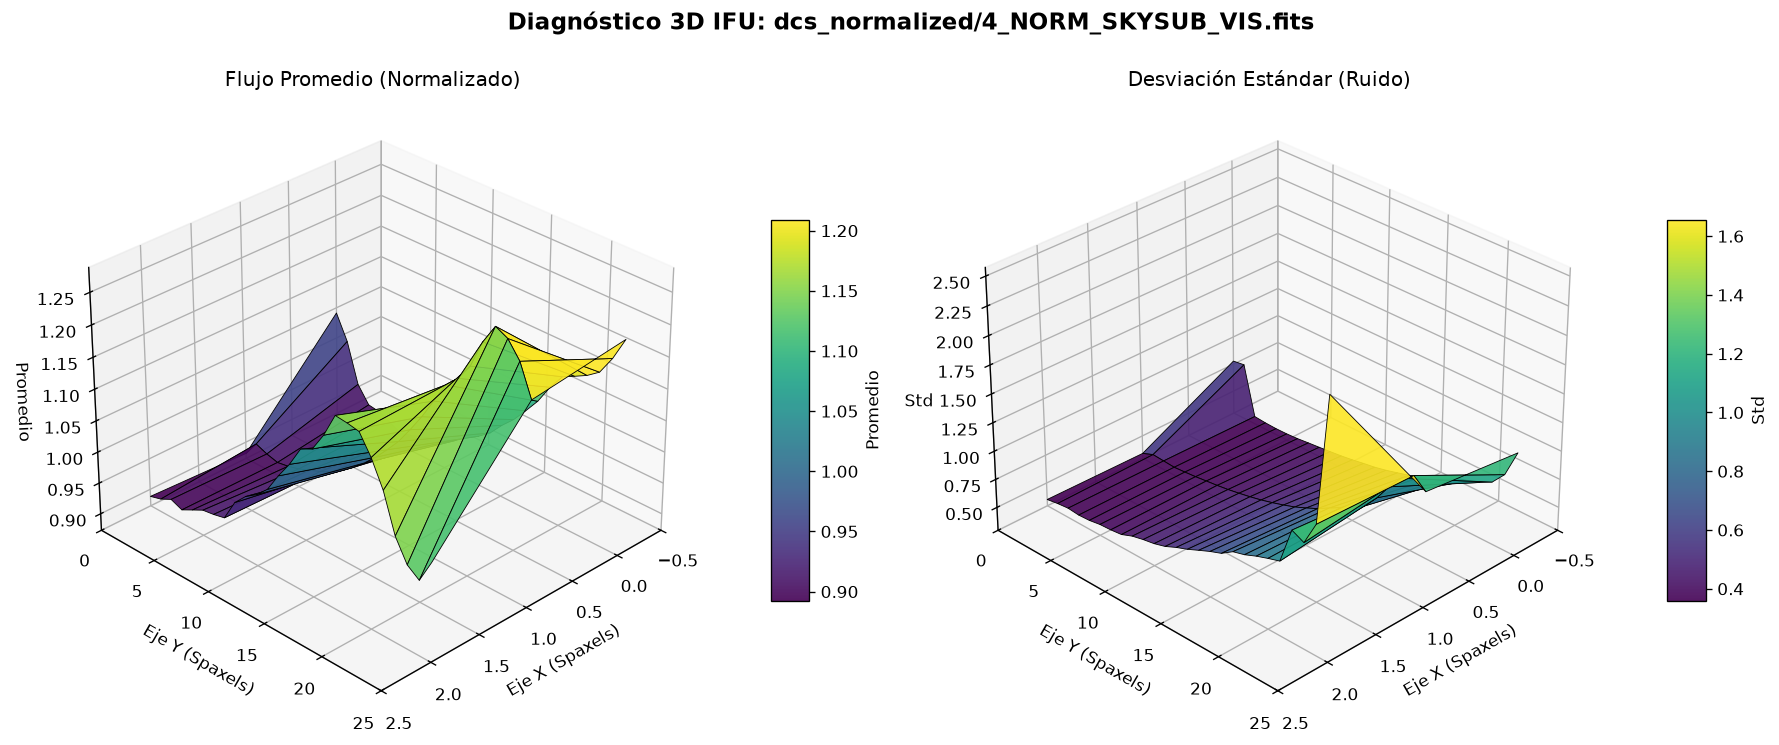

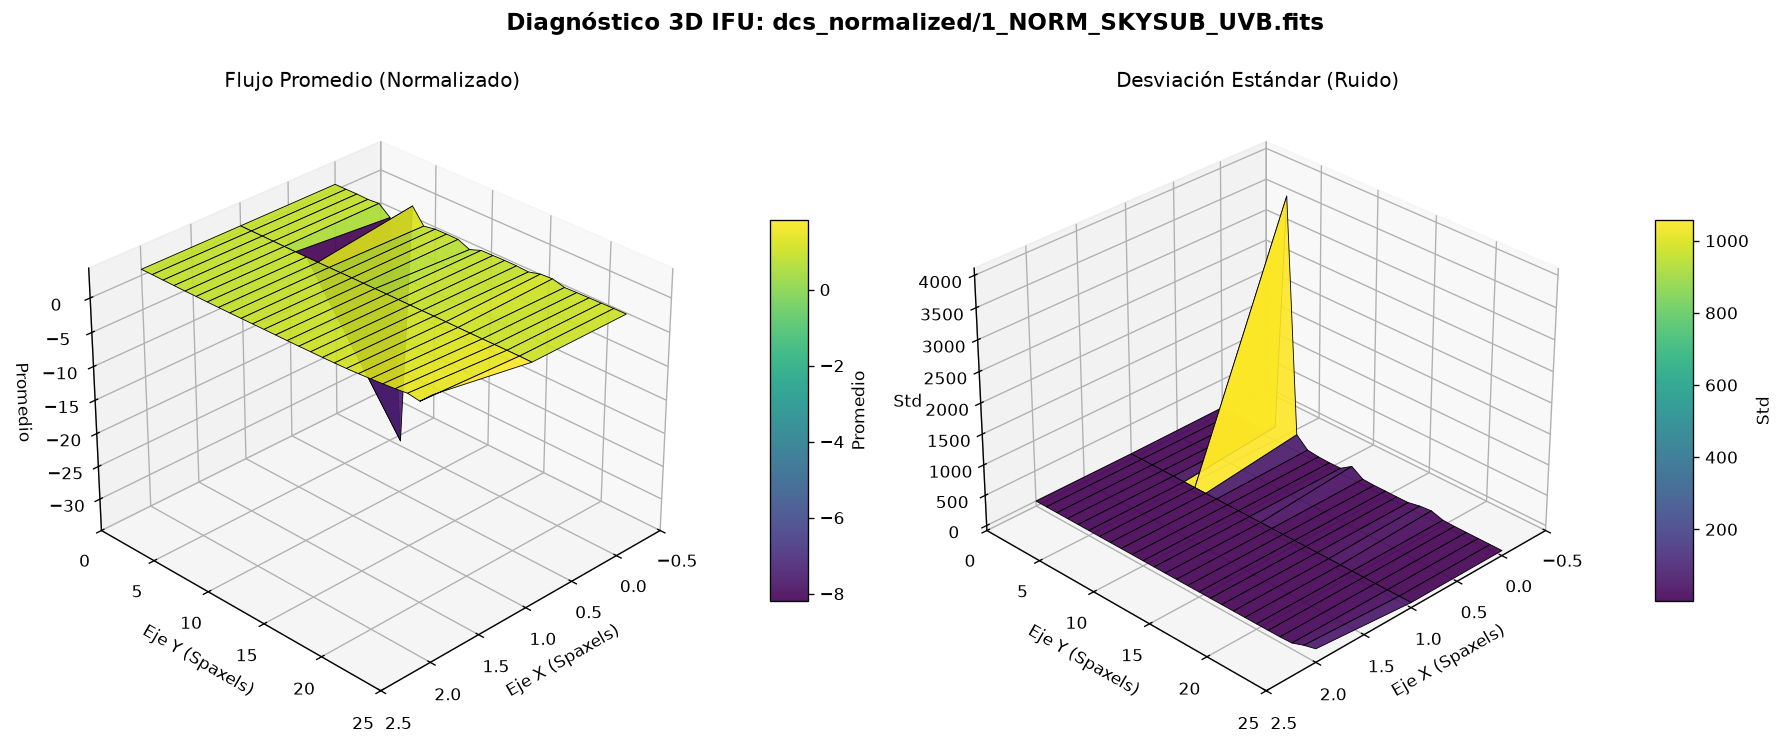

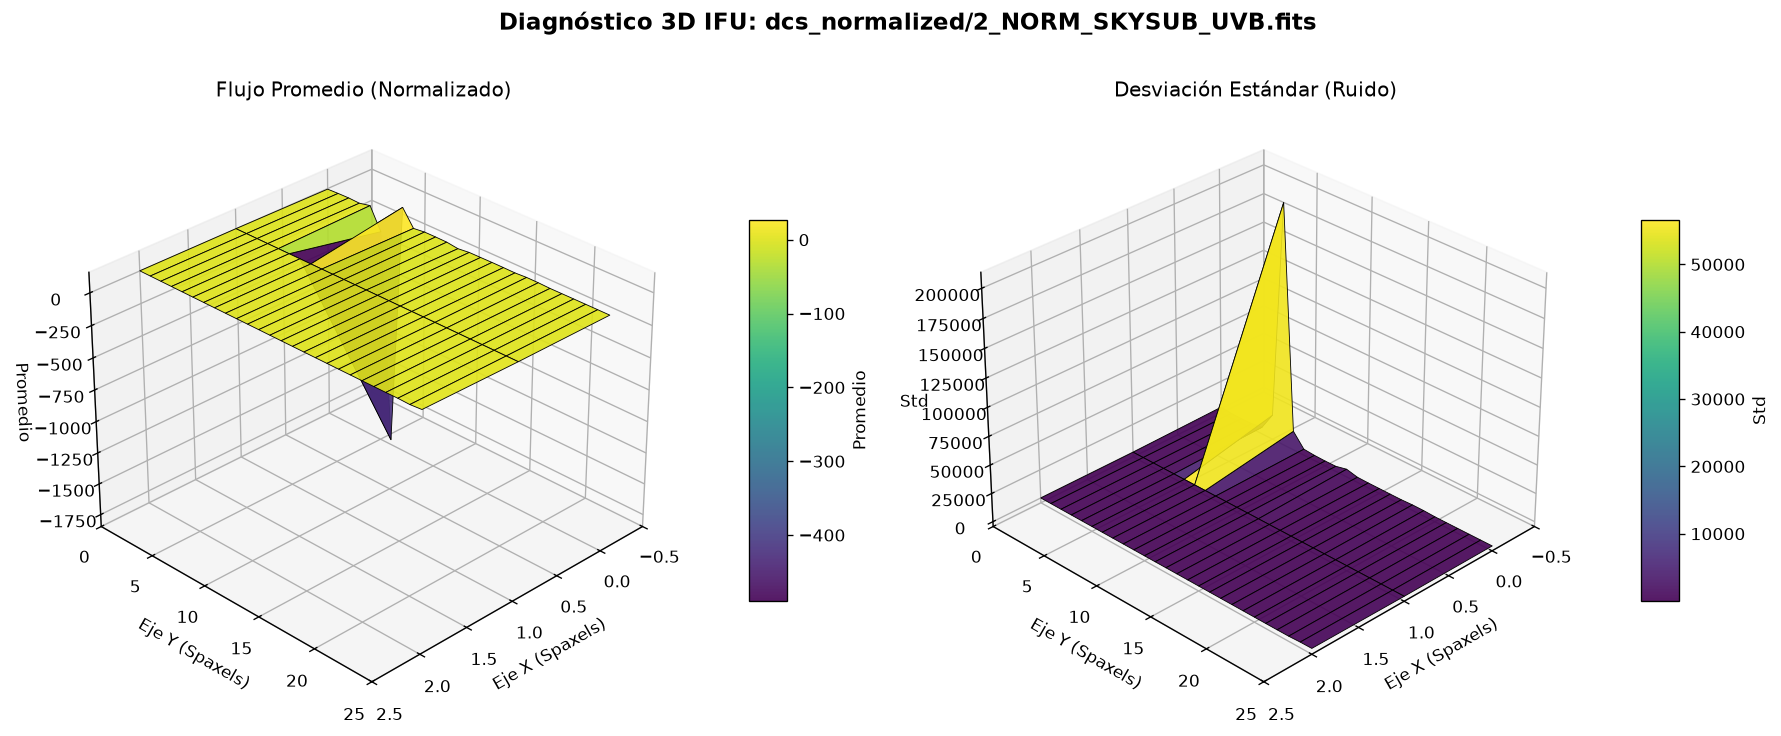

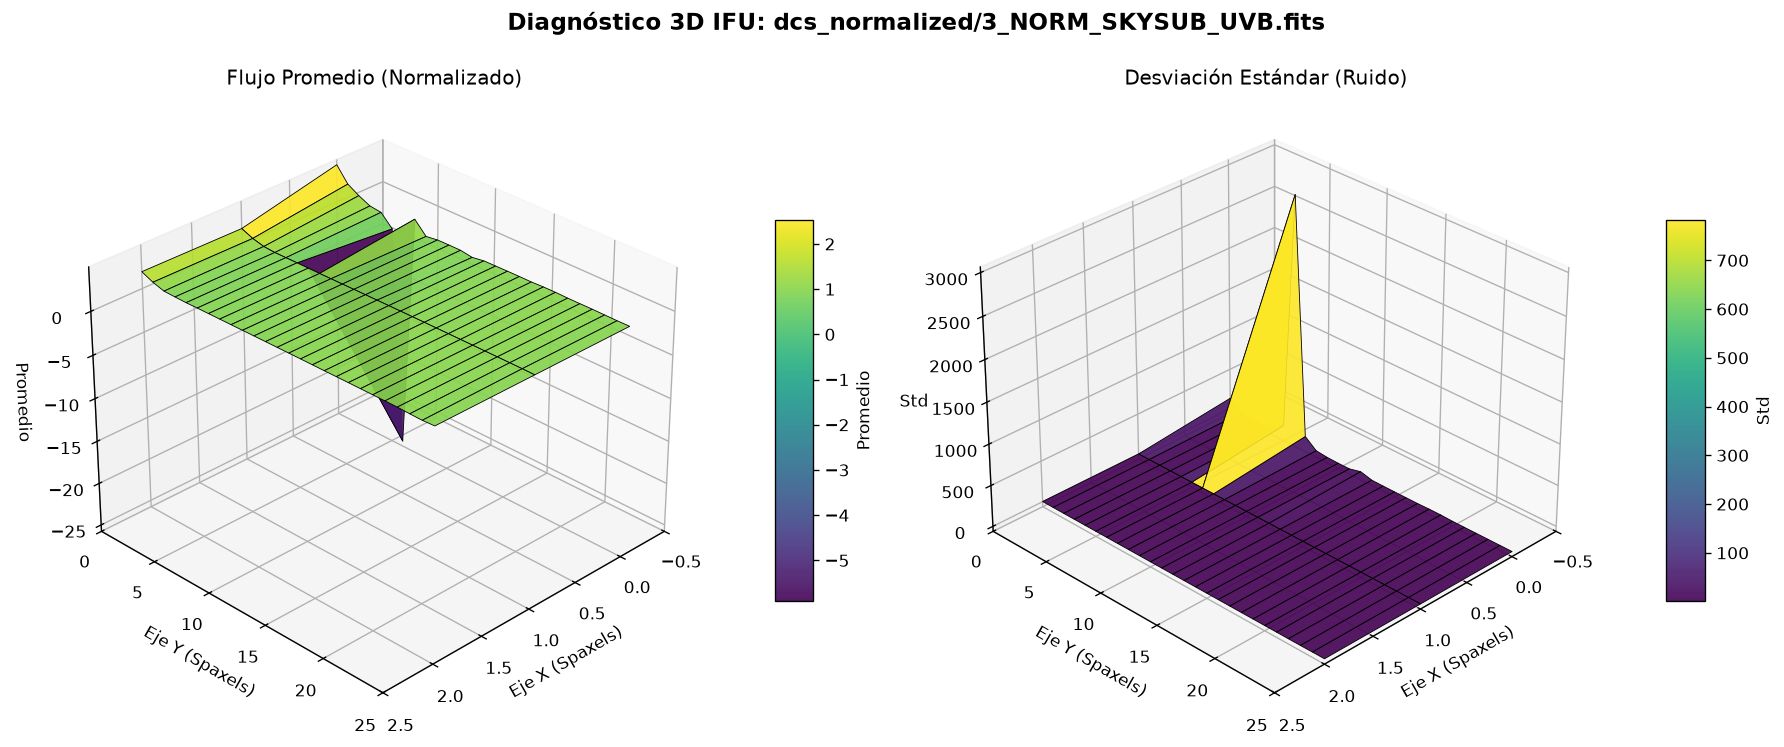

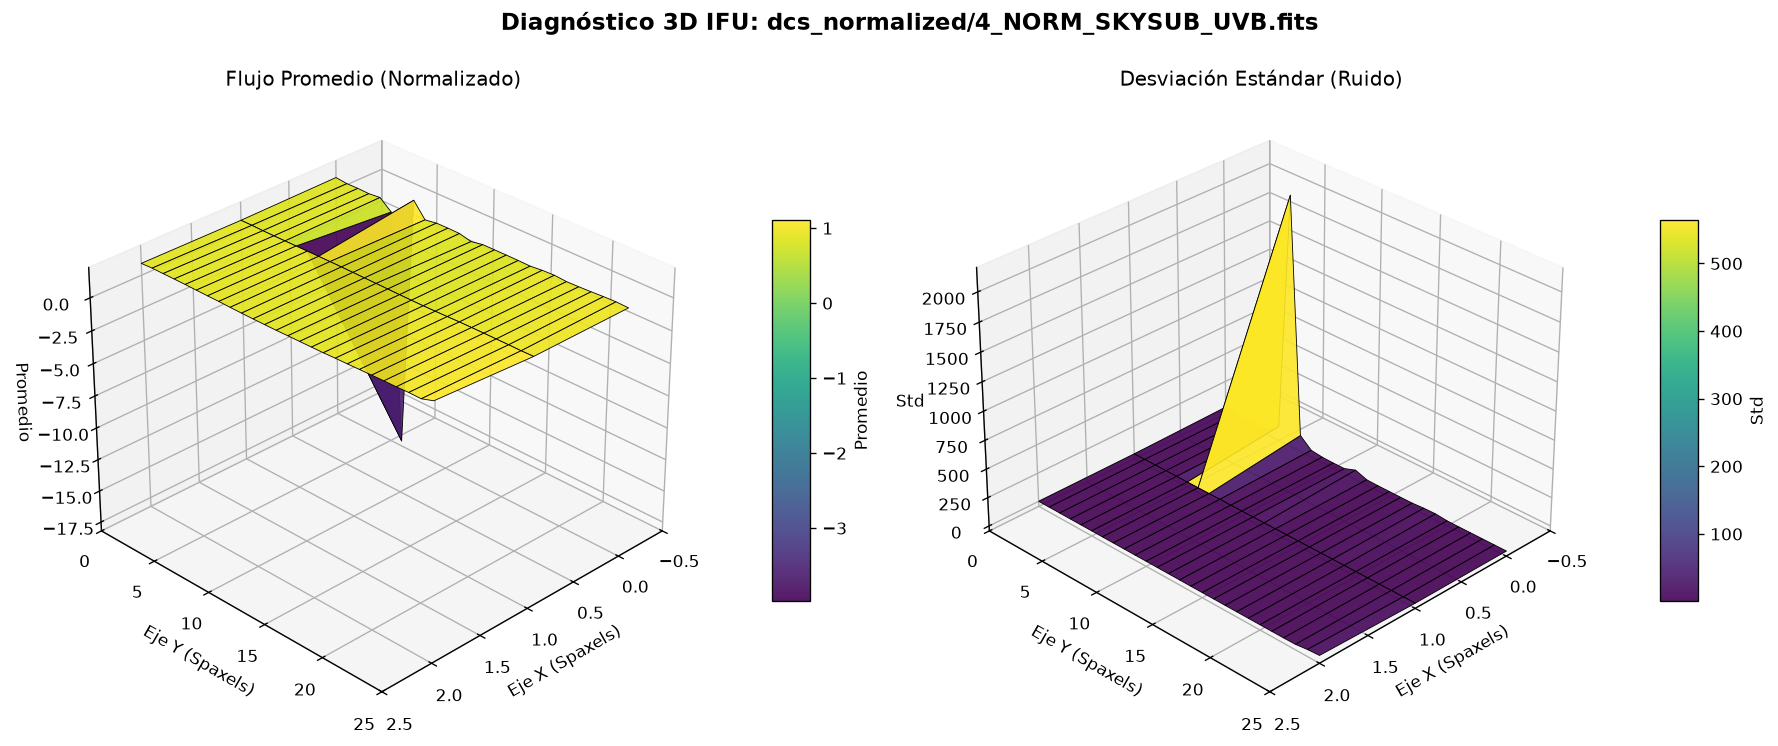

In [10]:
import os
pointings = [1, 2, 3, 4]
arms = ['NIR', 'VIS', 'UVB']
carpeta = 'dcs_normalized'

for arm in arms:
    for pt in pointings:
        # Construcción correcta del f-string con la ruta
        archivo_fits = f"{carpeta}/{pt}_NORM_SKYSUB_{arm}.fits"
        graficar_mapa_3d(archivo_fits) 